# Bài tập 2 — Xây dựng mô hình hồi quy cho dữ liệu bảng

## Nội dung

1. Phân tích phân phối, ngoại lệ và tương quan của ba đặc trưng trong bộ Diabetes.
2. So sánh các bộ đặc trưng bằng Linear Regression.
3. So sánh năm thuật toán hồi quy và lựa chọn đặc trưng riêng cho từng mô hình.
4. Xây dựng Pipeline dự đoán giá nhà, so sánh Feature Engineering, Feature Selection và các thuật toán.

Chất lượng dự đoán được đánh giá bằng MAE, MSE, RMSE và R². Tập test ngoài cùng được giữ riêng khi lựa chọn đặc trưng bằng validation trong train


# 1. Chuẩn bị dữ liệu

## Bước 1. Import thư viện

Sử dụng NumPy, pandas, matplotlib và scikit-learn.

In [ ]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GroupShuffleSplit, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
pd.set_option("display.max_columns", None)

## Bước 2. Nạp bộ dữ liệu Diabetes

Bộ dữ liệu có 442 mẫu, 10 đặc trưng và một target là mức độ tiến triển bệnh sau một năm. Các đặc trưng đã được chuẩn hóa sẵn.

In [ ]:
diabetes = load_diabetes(as_frame=True)

X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Ý nghĩa các cột

| Biến | Ý nghĩa |
|---|---|
| `age` | Tuổi |
| `sex` | Giới tính đã được mã hóa/chuẩn hóa |
| `bmi` | Body Mass Index |
| `bp` | Huyết áp trung bình |
| `s1`–`s6` | Các chỉ số huyết thanh |
| `target` | Mức độ tiến triển bệnh sau một năm |

## Bước 3. Kiểm tra cấu trúc dữ liệu

Kiểm tra kích thước, kiểu dữ liệu, giá trị thiếu và hàng trùng.

In [ ]:
print("Shape:", df.shape)
print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nSố giá trị thiếu:")
print(df.isnull().sum())

print("\nSố dòng trùng lặp:", df.duplicated().sum())

Shape: (442, 11)

Kiểu dữ liệu:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

Số giá trị thiếu:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Số dòng trùng lặp: 0


### Nhận xét

Dữ liệu không có giá trị thiếu hoặc hàng trùng theo các phép kiểm tra trên. Các biến đầu vào ở thang đã chuẩn hóa, giá trị âm không phải giá trị âm của đại lượng đo gốc.

## Bước 4. Thống kê mô tả

Quan sát count, mean, std, min, max và các phân vị.

In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


# 2. Bài 1 — Phân tích khám phá dữ liệu Diabetes

## Yêu cầu

Chọn 3 feature và nhận xét phân phối, outlier, tương quan với target và scatter plot. Chọn bmi, bp, s5. Các biểu đồ của toàn bộ biến hỗ trợ phân tích tổng quan.

## Bước 5. Phân phối các biến

Histogram giúp xem vùng tập trung, độ lệch và các giá trị xa phần lớn dữ liệu.

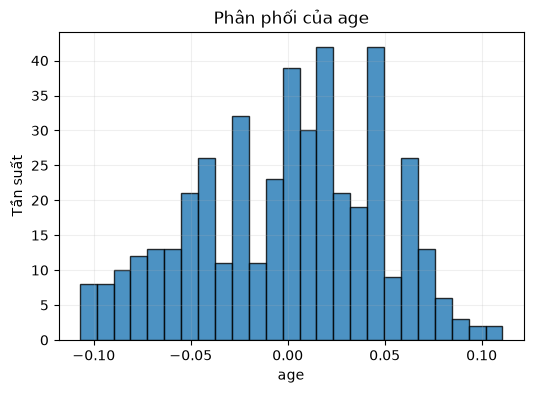

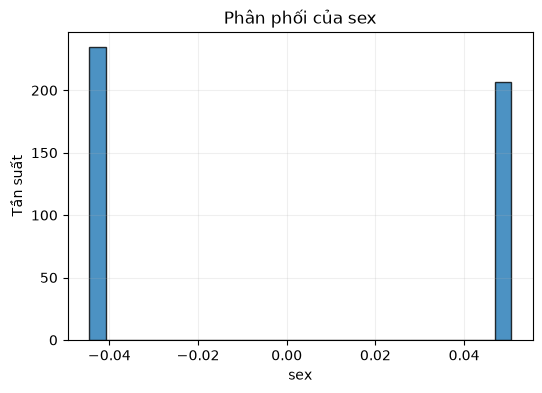

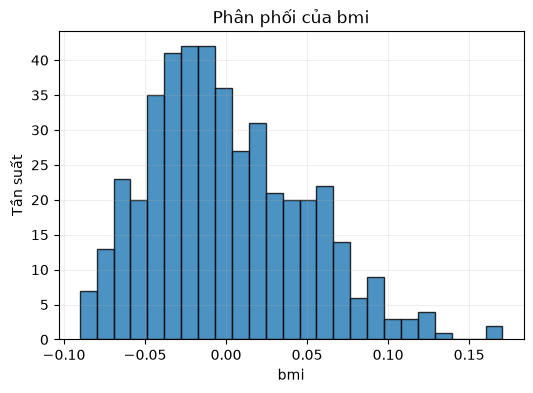

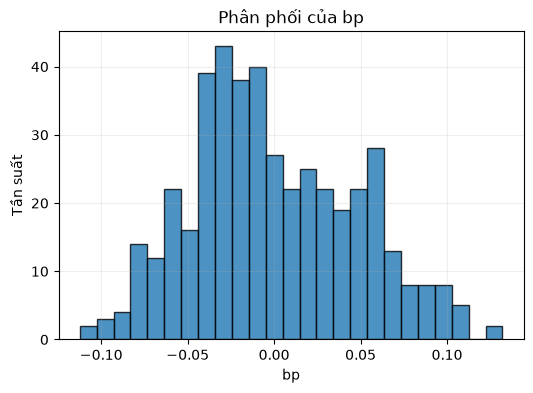

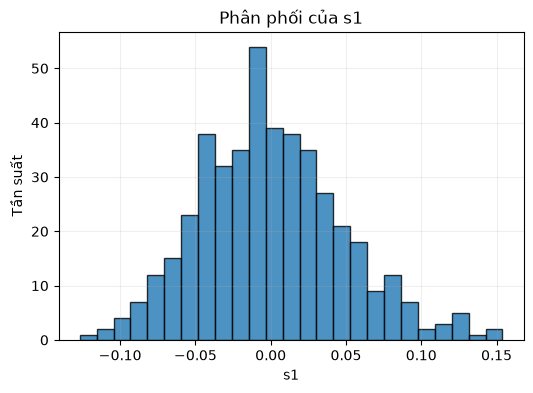

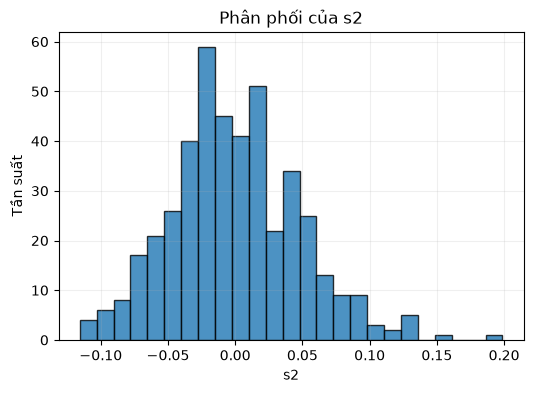

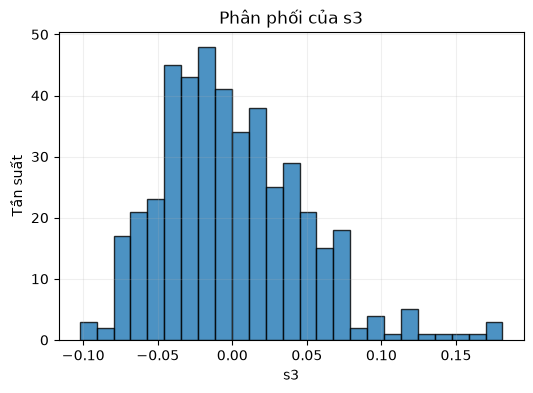

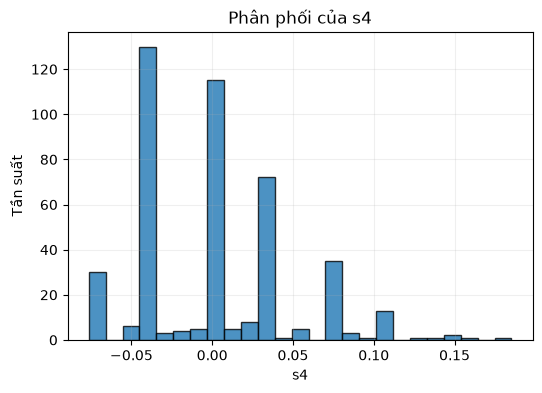

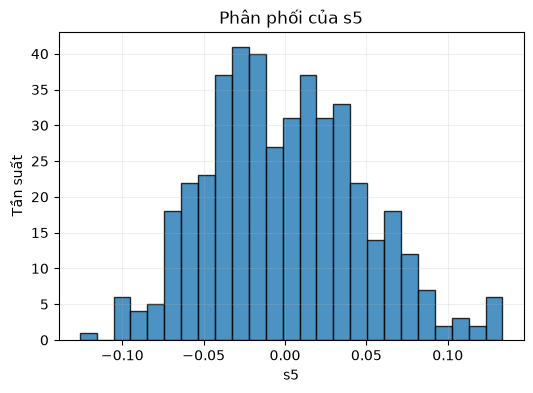

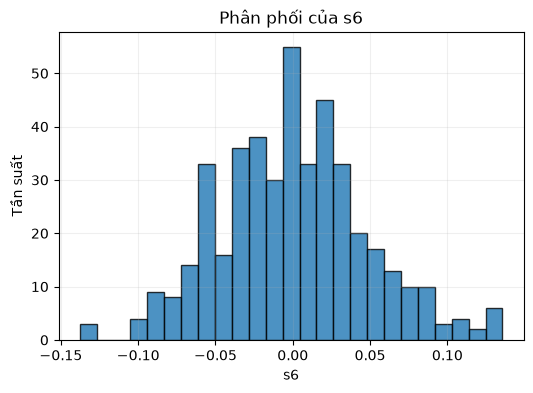

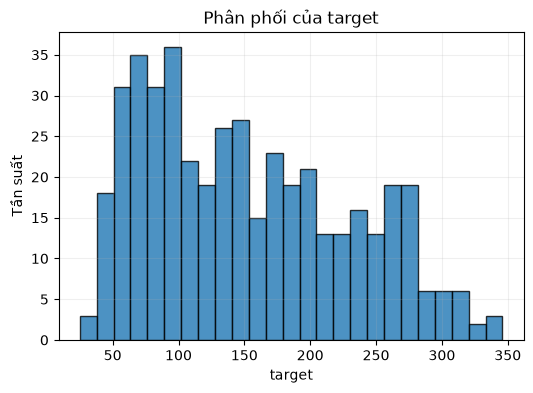

In [ ]:
feature_cols = X.columns.tolist()

for col in feature_cols + ["target"]:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=25, edgecolor="black", alpha=0.8)
    plt.title(f"Phân phối của {col}")
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.grid(alpha=0.2)
    plt.show()
    plt.close()

## Bước 6. Phát hiện ngoại lệ bằng IQR


\[
IQR=Q_3-Q_1
\]

Đánh dấu ngoại lệ ngoài khoảng \([Q_1-1.5IQR,\;Q_3+1.5IQR]\). Không tự động xóa quan sát chỉ vì quy tắc này.

In [ ]:
outlier_summary = []

for col in feature_cols + ["target"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Số ngoại lệ theo IQR", "Ngưỡng dưới", "Ngưỡng trên"]
)

display(outlier_df)

,Biến,Số ngoại lệ theo IQR,Ngưỡng dưới,Ngưỡng trên
0,age,0,-0.150362,0.151139
1,sex,0,-0.187624,0.193663
2,bmi,3,-0.132445,0.129464
3,bp,0,-0.145106,0.144094
4,s1,8,-0.128157,0.122267
5,s2,7,-0.120663,0.120149
6,s3,7,-0.131760,0.125954
7,s4,2,-0.150197,0.145012
8,s5,4,-0.131762,0.130949
9,s6,9,-0.124823,0.119561


## Bước 7. Phân tích tương quan

Pearson nằm trong [-1, 1]. Trị tuyệt đối lớn thể hiện liên hệ tuyến tính mạnh; dấu cho biết xu hướng tăng hoặc giảm.

In [ ]:
corr = df.corr(numeric_only=True)

target_corr = corr["target"].drop("target").sort_values(key=np.abs, ascending=False)

print("Tương quan với target:")
display(target_corr.to_frame("corr_with_target"))

Tương quan với target:


,corr_with_target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


## Bước 8. Ma trận tương quan

Xem tương quan giữa các đầu vào để nhận biết thông tin tương tự nhau và nguy cơ đa cộng tuyến.

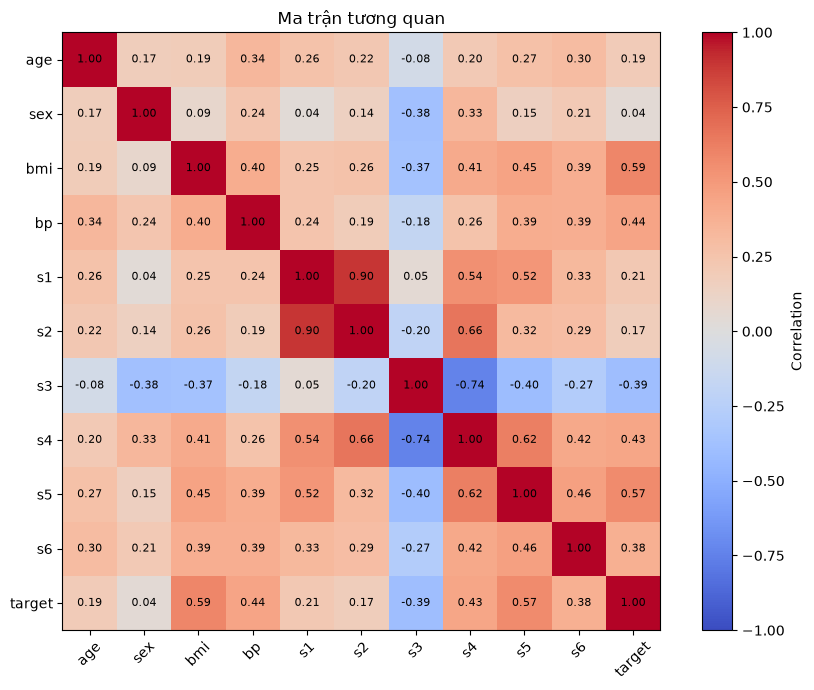

In [ ]:
# Vẽ ma trận tương quan
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Ma trận tương quan")
plt.tight_layout()
plt.show()
plt.close()

## Bước 9. Quan hệ giữa từng feature và target

Scatter plot giúp quan sát xu hướng, độ phân tán và khả năng xuất hiện quan hệ phi tuyến.

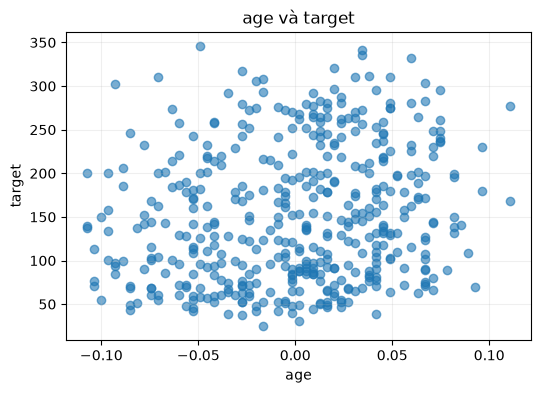

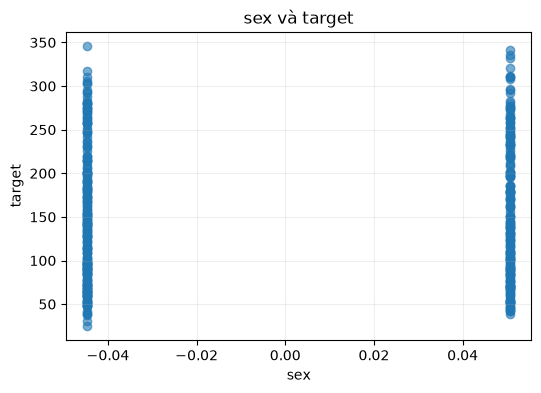

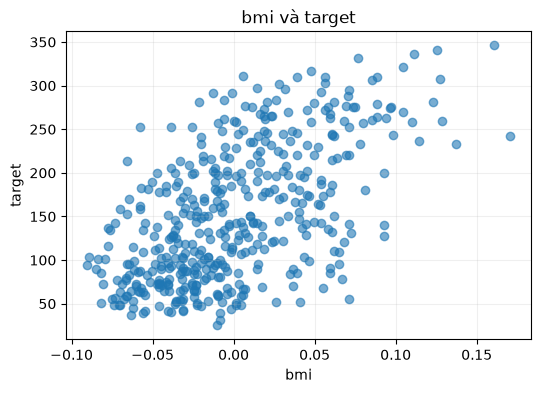

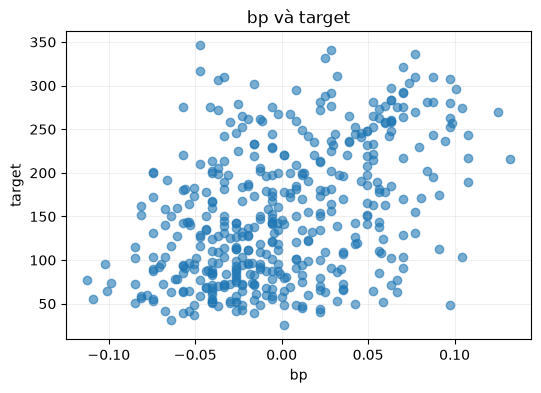

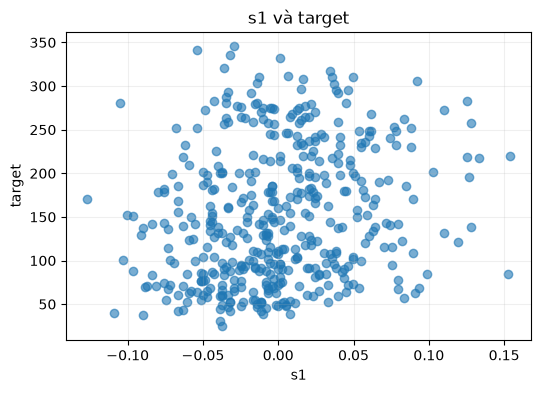

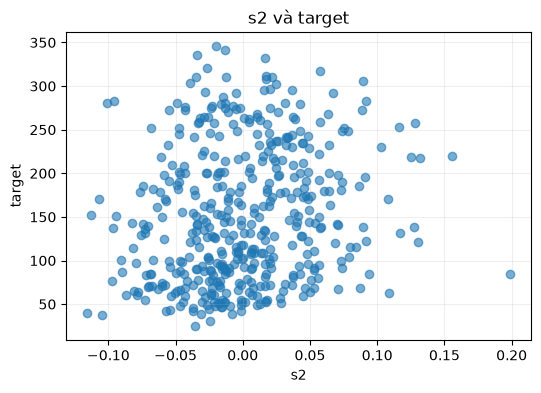

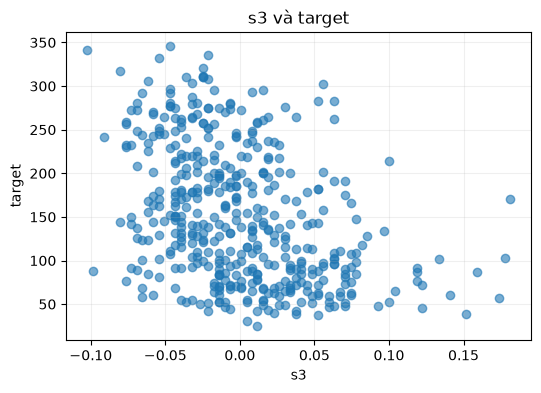

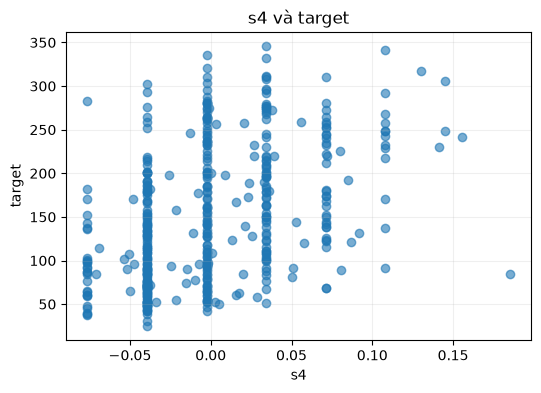

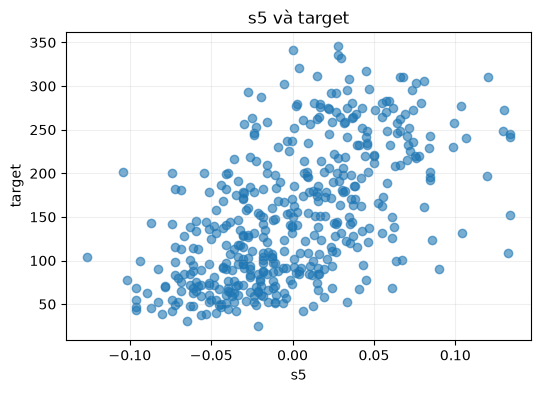

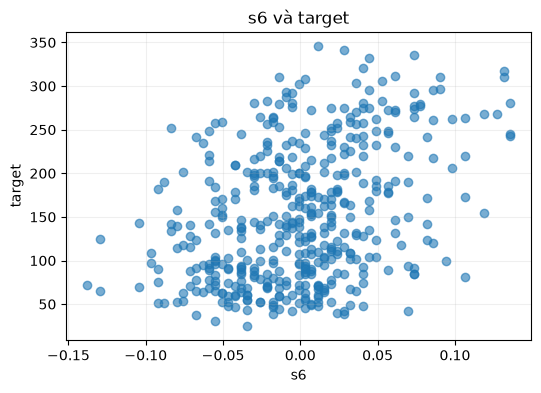

In [ ]:
for col in feature_cols:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["target"], alpha=0.6)
    plt.xlabel(col)
    plt.ylabel("target")
    plt.title(f"{col} và target")
    plt.grid(alpha=0.2)
    plt.show()
    plt.close()

## Bước 10. Tổng hợp 3 đặc trưng được chọn

Tóm tắt số ngoại lệ và tương quan của bmi, bp, s5.

In [ ]:
selected_eda = ["bmi", "bp", "s5"]
eda_summary = outlier_df.set_index("Biến").loc[selected_eda].copy()
eda_summary["Tương quan với target"] = corr.loc[selected_eda, "target"]
display(eda_summary)

,Số ngoại lệ theo IQR,Ngưỡng dưới,Ngưỡng trên,Tương quan với target
Biến,,,,
bmi,3,-0.132445,0.129464,0.586450
bp,0,-0.145106,0.144094,0.441482
s5,4,-0.131762,0.130949,0.565883


### Nhận xét bài 1

- **bmi:** có đuôi về phía giá trị cao; 3 ngoại lệ IQR; tương quan dương khoảng 0,5865; scatter có xu hướng tăng nhưng vẫn phân tán.
- **bp:** tập trung ở vùng giữa, có các mức rời rạc; không có ngoại lệ IQR; tương quan dương khoảng 0,4415.
- **s5:** tương đối tập trung quanh vùng giữa; 4 ngoại lệ IQR; tương quan dương khoảng 0,5659.

Cả ba biến đều có liên hệ tuyến tính dương với target. Cùng một giá trị đầu vào vẫn có nhiều mức target. Tương quan không chứng minh nhân quả.

### Trực quan hóa các điểm ngoại lệ

Ngoại lệ được xác định riêng theo từng feature bằng IQR. Điểm đỏ không đồng nghĩa target sai hoặc residual lớn. Feature của Diabetes ở thang đã biến đổi sẵn. Giữ nguyên dữ liệu để các thí nghiệm vẫn so trên cùng mẫu.

## Bước 11. Liệt kê ngưỡng và đúng các hàng ngoại lệ

Index là nhãn hàng gốc bắt đầu từ 0. Bảng cho biết feature nào vượt ngưỡng và target của chính hàng đó.

In [ ]:
outlier_detail_rows = []
for col in selected_eda:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    print(f"{col}: {mask.sum()} ngoại lệ; ngưỡng [{lower:.6f}, {upper:.6f}]")
    for row_index in df.index[mask]:
        outlier_detail_rows.append({"Feature": col, "Index": row_index,
            "Giá trị feature": df.loc[row_index, col],
            "Target": df.loc[row_index, "target"],
            "Ngưỡng dưới": lower, "Ngưỡng trên": upper})
outlier_details = pd.DataFrame(outlier_detail_rows)
display(outlier_details)

bmi: 3 ngoại lệ; ngưỡng [-0.132445, 0.129464]
bp: 0 ngoại lệ; ngưỡng [-0.145106, 0.144094]
s5: 4 ngoại lệ; ngưỡng [-0.131762, 0.130949]


,Feature,Index,Giá trị feature,Target,Ngưỡng dưới,Ngưỡng trên
0,bmi,256,0.160855,346.0,-0.132445,0.129464
1,bmi,366,0.137143,233.0,-0.132445,0.129464
2,bmi,367,0.170555,242.0,-0.132445,0.129464
3,s5,23,0.133597,245.0,-0.131762,0.130949
4,s5,169,0.133597,152.0,-0.131762,0.130949
5,s5,322,0.133397,242.0,-0.131762,0.130949
6,s5,353,0.132376,109.0,-0.131762,0.130949


## Bước 12. Boxplot và scatter tô đỏ ngoại lệ

Đường nét đứt là ngưỡng IQR; nhãn nhỏ là index. Boxplot dùng offset dọc nhẹ để các điểm có giá trị gần nhau không che nhau, không đổi tọa độ feature.

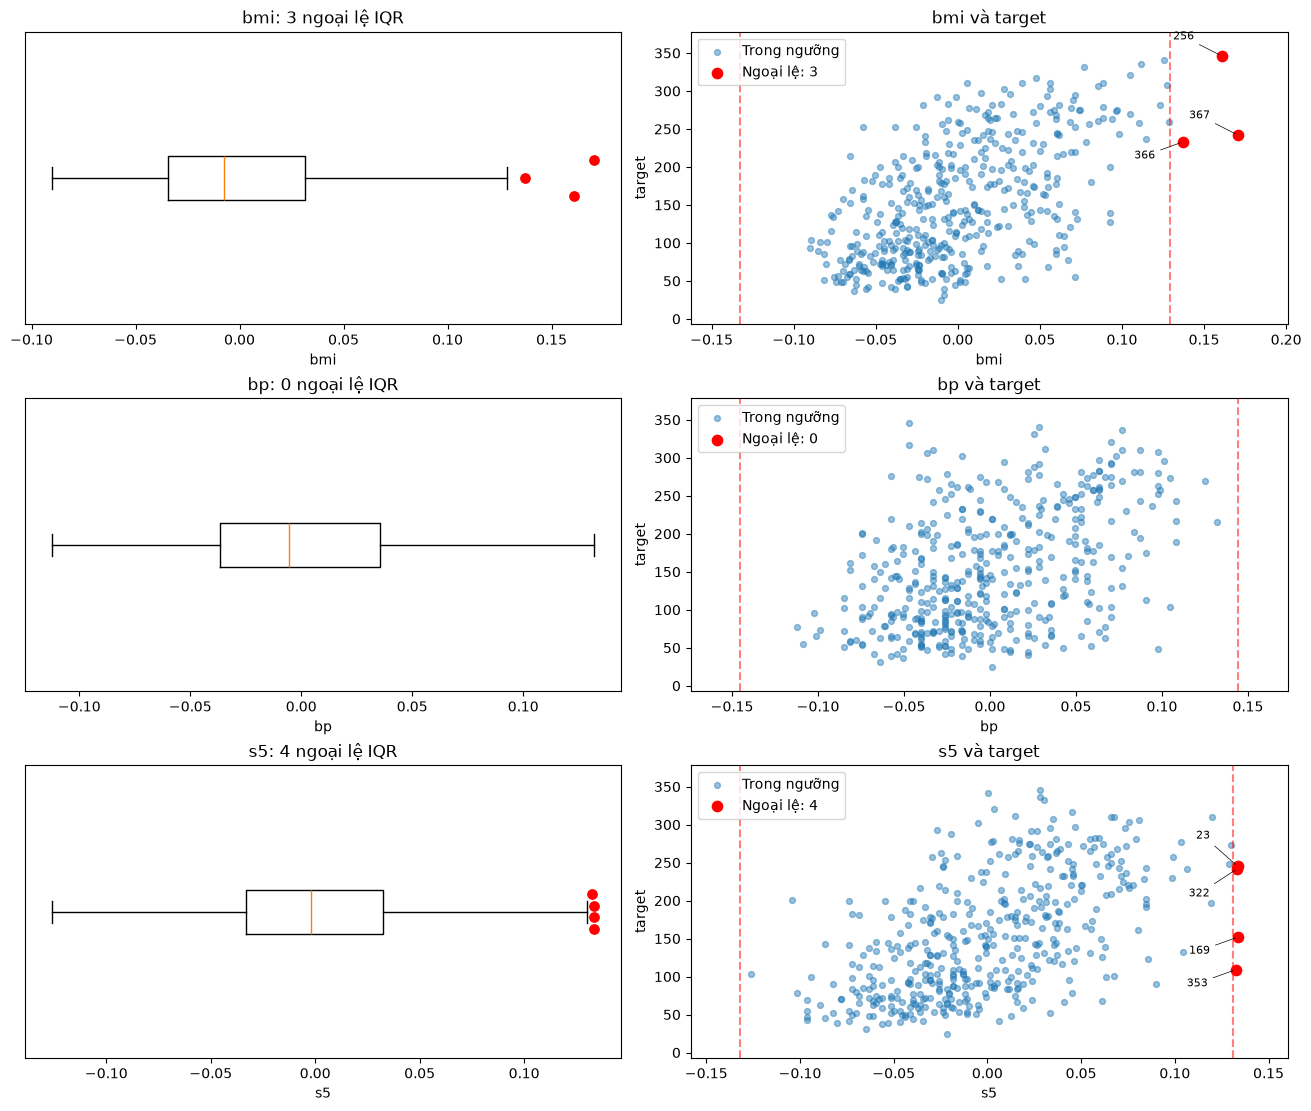

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(13, 11), layout="constrained")
for row, col in enumerate(selected_eda):
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    count = int(mask.sum())
    ax = axes[row, 0]
    ax.boxplot(df[col], orientation="horizontal", whis=1.5, showfliers=False)
    ax.scatter(df.loc[mask, col], np.linspace(.94, 1.06, count),
               color="red", s=45, zorder=3)
    ax.set(title=f"{col}: {count} ngoại lệ IQR", xlabel=col, yticks=[])
    ax = axes[row, 1]
    ax.scatter(df.loc[~mask, col], df.loc[~mask, "target"],
               alpha=.45, s=18, label="Trong ngưỡng")
    ax.scatter(df.loc[mask, col], df.loc[mask, "target"],
               color="red", s=55, label=f"Ngoại lệ: {count}")
    ax.axvline(lower, color="red", linestyle="--", alpha=.5)
    ax.axvline(upper, color="red", linestyle="--", alpha=.5)
    for order, row_index in enumerate(df.index[mask]):
        dy = {23: 20, 322: -20}.get(int(row_index), 12 if order % 2 == 0 else -12)
        ax.annotate(str(row_index), (df.loc[row_index, col], df.loc[row_index, "target"]),
                    xytext=(-20, dy), textcoords="offset points", ha="right",
                    fontsize=8, arrowprops={"arrowstyle": "-", "lw": .5})
    ax.set(xlabel=col, ylabel="target", title=f"{col} và target")
    ax.margins(x=.1, y=.1)
    ax.legend()
plt.show()
plt.close("all")

# 3. Bài 2 — So sánh các bộ đặc trưng

## Yêu cầu

Huấn luyện Linear Regression với: bmi; bmi + bp; top 5 theo tương quan; toàn bộ 10 feature. So sánh MAE, RMSE và R².

## Bước 13. Chia train/test

Sử dụng test_size=0,2 và random_state=42. Chia một lần để các mô hình dùng cùng các mẫu.

In [ ]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (353, 10)
Test: (89, 10)


## Bước 14. Chọn top 5 đặc trưng

Tính |Pearson| chỉ trên train để nhãn test không ảnh hưởng việc chọn biến. Vì vậy danh sách có thể khác khi tính trên toàn bộ dữ liệu.

In [ ]:
abs_corr_train = X_train.corrwith(y_train).abs()
top_features = abs_corr_train.sort_values(ascending=False).head(5).index.tolist()
print("Top 5:", top_features)
display(abs_corr_train.sort_values(ascending=False).to_frame("abs_corr_train"))

Top 5: ['bmi', 's5', 'bp', 's4', 's6']


,abs_corr_train
bmi,0.604751
s5,0.552183
bp,0.444770
s4,0.425094
s6,0.390363
s3,0.384000
s1,0.199547
age,0.196510
s2,0.154922
sex,0.007116


## Bước 15. Hàm đánh giá hồi quy

Tính bốn chỉ số đánh giá bằng cùng một hàm. RMSE là căn bậc hai của MSE; metric được tính trên cùng thang target.

In [ ]:
def metric_values(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {'MAE': mean_absolute_error(actual, predicted), 'MSE': mse,
            'RMSE': np.sqrt(mse), 'R2': r2_score(actual, predicted)}

## Bước 16. Huấn luyện và dự đoán với 4 bộ đầu vào

Trong từng trường hợp: khai báo mô hình → fit trên train → predict trên test → tính các chỉ số.

In [ ]:
feature_sets = {
    "bmi": ["bmi"],
    "bmi + bp": ["bmi", "bp"],
    "Top 5 theo train": top_features,
    "Toàn bộ 10": X.columns.tolist()
}
feature_results = []
feature_models = {}
feature_predictions = {}

for name, columns in feature_sets.items():
    model = LinearRegression()
    model.fit(X_train[columns], y_train)
    prediction = model.predict(X_test[columns])
    train_prediction = model.predict(X_train[columns])
    row = {"Bộ đặc trưng": name, **metric_values(y_test, prediction)}
    row["RMSE_train"] = np.sqrt(mean_squared_error(y_train, train_prediction))
    row["R2_train"] = r2_score(y_train, train_prediction)
    feature_results.append(row)
    feature_models[name] = model
    feature_predictions[name] = prediction

comparison_features = pd.DataFrame(feature_results)
display(comparison_features)

,Bộ đặc trưng,MAE,MSE,RMSE,R2,RMSE_train,R2_train
0,bmi,52.259976,4061.825928,63.732456,0.233350,62.081500,0.365724
1,bmi + bp,50.044115,3740.507020,61.159685,0.293998,59.563897,0.416125
2,Top 5 theo train,44.328840,2899.742682,53.849259,0.452688,55.927071,0.485248
3,Toàn bộ 10,42.794095,2900.193628,53.853446,0.452603,53.558843,0.527919


## Bước 17. Phân tích hệ số baseline

Baseline dùng toàn bộ 10 feature gốc. Hệ số được đọc trên thang đầu vào đã chuẩn hóa của dữ liệu Diabetes.

In [ ]:
baseline_model = feature_models["Toàn bộ 10"]
baseline_pred = feature_predictions["Toàn bộ 10"]
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": baseline_model.coef_
}).sort_values("Coefficient", key=np.abs, ascending=False)

print("Intercept:", baseline_model.intercept_)
display(coef_df)

Intercept: 151.34560453985995


,Feature,Coefficient
4,s1,-931.488846
8,s5,736.198859
2,bmi,542.428759
5,s2,518.062277
3,bp,347.703844
7,s4,275.317902
1,sex,-241.964362
6,s3,163.419983
9,s6,48.670657
0,age,37.904021


### Nhận xét bài 2

Chỉ dùng bmi hoặc bmi + bp cho sai số lớn hơn hai bộ còn lại. Top 5 và 10 feature có RMSE gần như ngang nhau, nhưng 10 feature có MAE thấp hơn. Không coi chênh lệch RMSE rất nhỏ là cải thiện chắc chắn. Cần cân nhắc sai số và số đầu vào cần thu thập.

# 4. Bài 3 — So sánh các thuật toán hồi quy

## Yêu cầu

So sánh Ridge, Decision Tree, SVR và Gradient Boosting với Linear Regression trên toàn bộ 10 đặc trưng.

## Bước 18. Khai báo các mô hình

Các tham số được đặt trước khi đánh giá. Pipeline học chuẩn hóa trên train. SVR chuẩn hóa target trên train và chuyển dự đoán về thang gốc.

In [ ]:
diabetes_models = {
        'Linear Regression': LinearRegression(),
        'Ridge Regression': Ridge(alpha=1.0),
        'Decision Tree': DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=SEED),
        'SVR': TransformedTargetRegressor(regressor=SVR(kernel='rbf', C=10, epsilon=0.1), transformer=StandardScaler()),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, random_state=SEED)
    }

display(pd.DataFrame({
    "Mô hình": list(diabetes_models),
    "Cấu hình": [str(model) for model in diabetes_models.values()]
}))

,Mô hình,Cấu hình
0,Linear Regression,LinearRegression()
1,Ridge Regression,Ridge()
2,Decision Tree,"DecisionTreeRegressor(max_depth=4, min_samples..."
3,SVR,TransformedTargetRegressor(regressor=SVR(C=10)...
4,Gradient Boosting,"GradientBoostingRegressor(learning_rate=0.05, ..."


## Bước 19. Huấn luyện, dự đoán và đánh giá

Giữ nguyên các mẫu train/test của bài 2.

In [ ]:
algorithm_results = []
algorithm_predictions = {}

for name, regressor in diabetes_models.items():
    model = Pipeline([
        ("scale", StandardScaler()),
        ("model", clone(regressor))
    ])
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    train_prediction = model.predict(X_train)
    row = {"Mô hình": name, **metric_values(y_test, prediction)}
    row["RMSE_train"] = np.sqrt(mean_squared_error(y_train, train_prediction))
    row["R2_train"] = r2_score(y_train, train_prediction)
    algorithm_results.append(row)
    algorithm_predictions[name] = prediction

comparison_algorithms = pd.DataFrame(algorithm_results).sort_values("RMSE")
display(comparison_algorithms)

,Mô hình,MAE,MSE,RMSE,R2,RMSE_train,R2_train
4,Gradient Boosting,42.822271,2797.768327,52.893935,0.471935,41.524263,0.716236
1,Ridge Regression,42.811999,2892.014566,53.777454,0.454147,53.575145,0.527632
0,Linear Regression,42.794095,2900.193628,53.853446,0.452603,53.558843,0.527919
2,Decision Tree,43.441655,2997.896425,54.753049,0.434162,50.820926,0.574951
3,SVR,46.382479,3885.291468,62.332106,0.266670,33.157665,0.819065


## Bước 20. Đánh giá bổ sung bằng cross-validation

5-fold CV chỉ trong train giúp xem kết quả biến động qua nhiều lần chia. Tập test không được dùng để tinh chỉnh tham số.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = []

for name, regressor in diabetes_models.items():
    model = Pipeline([("scale", StandardScaler()), ("model", clone(regressor))])
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error", "r2": "r2"}
    )
    cv_results.append({
        "Mô hình": name,
        "CV_MAE": -scores["test_mae"].mean(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_RMSE_std": scores["test_rmse"].std(),
        "CV_R2": scores["test_r2"].mean()
    })

display(pd.DataFrame(cv_results).sort_values("CV_RMSE"))

,Mô hình,CV_MAE,CV_RMSE,CV_RMSE_std,CV_R2
1,Ridge Regression,44.998879,55.374175,2.373206,0.480784
0,Linear Regression,45.048200,55.394633,2.361496,0.480365
4,Gradient Boosting,47.691957,58.478679,2.901429,0.421958
2,Decision Tree,52.396163,65.365088,2.499651,0.274080
3,SVR,51.690481,67.331327,5.023096,0.231121


### Nhận xét bài 3

Gradient Boosting có RMSE test thấp nhất trong các cấu hình đã thử, nhưng Linear Regression có MAE thấp nhất. Ridge có CV_RMSE trung bình thấp nhất. SVR có sai số train thấp hơn nhiều so với test, nên cần xem xét khả năng khái quát của cấu hình.

Các thuật toán phi tuyến không mặc định tốt hơn mô hình tuyến tính. Kết quả giới hạn trong các tham số và cách chia đã dùng.

# 5. Tạo đặc trưng và phân tích sai số trên Diabetes

Tạo các đặc trưng mới và phân tích chất lượng dự đoán của mô hình baseline.

## Bước 21. Tạo đặc trưng bình phương

bmi² và bp² giúp mô hình tuyến tính theo hệ số mô tả độ cong.

In [ ]:
df_fe = df.copy()

df_fe["bmi_squared"] = df_fe["bmi"] ** 2
df_fe["bp_squared"] = df_fe["bp"] ** 2

display(df_fe[["bmi", "bmi_squared", "bp", "bp_squared"]].head())

,bmi,bmi_squared,bp,bp_squared
0,0.061696,0.003806,0.021872,0.000478
1,-0.051474,0.002650,-0.026328,0.000693
2,0.044451,0.001976,-0.005670,0.000032
3,-0.011595,0.000134,-0.036656,0.001344
4,-0.036385,0.001324,0.021872,0.000478


## Bước 22. Tạo đặc trưng tương tác

bmi × bp giúp biểu diễn sự kết hợp giữa hai đầu vào.

In [ ]:
df_fe["bmi_bp"] = df_fe["bmi"] * df_fe["bp"]

display(df_fe[["bmi", "bp", "bmi_bp"]].head())

,bmi,bp,bmi_bp
0,0.061696,0.021872,0.001349
1,-0.051474,-0.026328,0.001355
2,0.044451,-0.005670,-0.000252
3,-0.011595,-0.036656,0.000425
4,-0.036385,0.021872,-0.000796


## Bước 23. Tạo đặc trưng tổng hợp

Tính trung bình và độ lệch chuẩn của s1–s6 theo từng hàng; axis=1.

In [ ]:
serum_cols = ["s1", "s2", "s3", "s4", "s5", "s6"]

df_fe["serum_mean"] = df_fe[serum_cols].mean(axis=1)
df_fe["serum_std"] = df_fe[serum_cols].std(axis=1)

display(df_fe[serum_cols + ["serum_mean", "serum_std"]].head())

,s1,s2,s3,s4,s5,s6,serum_mean,serum_std
0,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,-0.020463,0.025510
1,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,-0.025538,0.057953
2,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,-0.022969,0.019065
3,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,0.008130,0.026286
4,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,-0.008925,0.024708


## Bước 24. Tương quan của các đặc trưng mới

Tương quan chỉ là thông tin khám phá, cần kiểm chứng bằng kết quả huấn luyện.

In [ ]:
new_features = [
    "bmi_squared",
    "bp_squared",
    "bmi_bp",
    "serum_mean",
    "serum_std"
]

new_corr = df_fe[new_features + ["target"]].corr()["target"].drop("target")
display(new_corr.sort_values(key=np.abs, ascending=False).to_frame("corr_with_target"))

,corr_with_target
serum_mean,0.380207
bmi_squared,0.252642
bp_squared,0.159666
bmi_bp,0.147114
serum_std,0.064110


## Bước 25. Huấn luyện mô hình sau Feature Engineering

Dùng lại đúng các hàng train/test của baseline.

In [ ]:
X_fe = df_fe.drop(columns=["target"])
X_train_fe = X_fe.loc[X_train.index]
X_test_fe = X_fe.loc[X_test.index]
fe_model = LinearRegression()
fe_model.fit(X_train_fe, y_train)
fe_pred = fe_model.predict(X_test_fe)

comparison_fe = pd.DataFrame([
    {"Model": "Baseline", **metric_values(y_test, baseline_pred)},
    {"Model": "Feature Engineering", **metric_values(y_test, fe_pred)}
])
display(comparison_fe)

,Model,MAE,MSE,RMSE,R2
0,Baseline,42.794095,2900.193628,53.853446,0.452603
1,Feature Engineering,42.385015,2808.534759,52.995611,0.469903


### Nhận xét

Feature Engineering cải thiện nhẹ MAE, RMSE và R² trên lần chia này. serum_mean là tổ hợp tuyến tính của s1–s6 nên không bổ sung dạng quan hệ mới khi vẫn giữ đầy đủ các cột này trong Linear Regression.

## Bước 26. Huấn luyện mô hình sau Feature Selection

Giữ top 5 đã chọn bằng train ở bài 2 và so với baseline.

In [ ]:
selected_model = LinearRegression()
selected_model.fit(X_train[top_features], y_train)
selected_pred = selected_model.predict(X_test[top_features])

comparison_selected = pd.DataFrame([
    {"Model": "Baseline", **metric_values(y_test, baseline_pred)},
    {"Model": "Feature Selection", **metric_values(y_test, selected_pred)}
])
display(comparison_selected)

,Model,MAE,MSE,RMSE,R2
0,Baseline,42.794095,2900.193628,53.853446,0.452603
1,Feature Selection,44.328840,2899.742682,53.849259,0.452688


## Bước 27. So sánh giá trị thực tế và dự đoán

Phần dư: \(e_i=y_i-\hat y_i\). Phần dư dương là dự đoán thấp hơn thực tế.

In [ ]:
result_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": baseline_pred,
    "Residual": y_test.values - baseline_pred
})

display(result_df.head(10))

,Actual,Predicted,Residual
0,219.0,139.547558,79.452442
1,70.0,179.517208,-109.517208
2,202.0,134.038756,67.961244
3,230.0,291.417029,-61.417029
4,111.0,123.789659,-12.789659
5,84.0,92.172347,-8.172347
6,242.0,258.232389,-16.232389
7,272.0,181.337321,90.662679
8,94.0,90.224113,3.775887
9,96.0,108.633759,-12.633759


## Bước 28. Actual vs Predicted

Điểm càng gần đường chéo thì dự đoán càng sát.

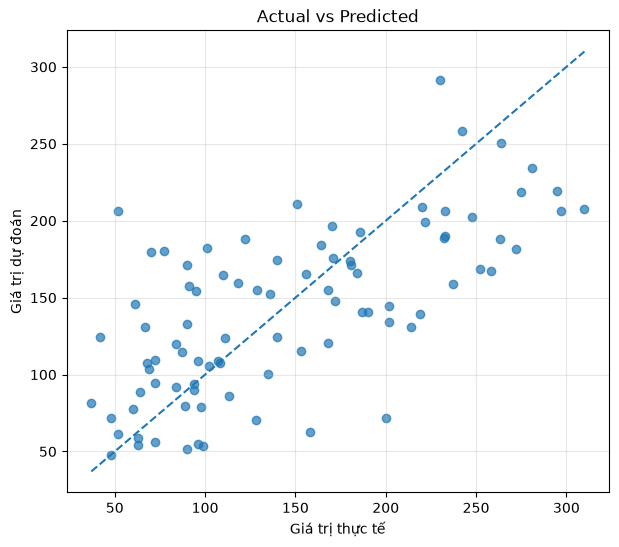

In [ ]:
# Trực quan hóa
plt.figure(figsize=(7, 6))
plt.scatter(y_test, baseline_pred, alpha=0.7)

min_value = min(y_test.min(), baseline_pred.min())
max_value = max(y_test.max(), baseline_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title("Actual vs Predicted")
plt.grid(alpha=0.3)
plt.show()
plt.close()

## Bước 29. Biểu đồ phần dư

Quan sát phần dư quanh 0, các cấu trúc dạng cong, hình phễu hoặc điểm sai lớn.

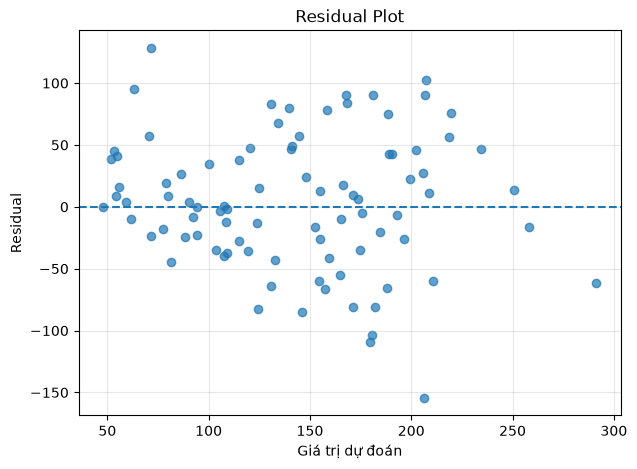

In [ ]:
residuals = y_test.values - baseline_pred

plt.figure(figsize=(7, 5))
plt.scatter(baseline_pred, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Giá trị dự đoán")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()
plt.close()

## Bước 30. Phân phối phần dư

Trung bình gần 0 chưa đủ để kết luận mô hình tốt vì sai số âm và dương có thể bù nhau.

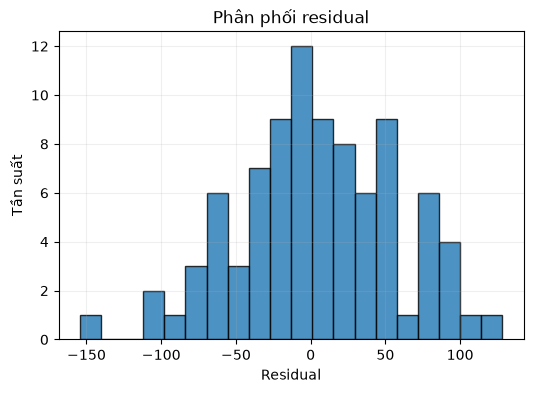

Mean residual: 3.912840375077805


In [ ]:
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=20, edgecolor="black", alpha=0.8)
plt.xlabel("Residual")
plt.ylabel("Tần suất")
plt.title("Phân phối residual")
plt.grid(alpha=0.2)
plt.show()

print("Mean residual:", np.mean(residuals))
plt.close()

# 6. Lựa chọn đặc trưng riêng cho từng mô hình Diabetes

Bước 19 là so thuật toán trên cùng 10 feature. Để chọn bộ đặc trưng phù hợp riêng cho từng mô hình, thử 5 bộ mốc × 5 thuật toán = 25 cấu hình trên validation, rồi chọn thêm dần từ 15 feature gốc và mới cho từng mô hình. Mỗi lượt thử thêm từng feature còn lại và giữ phương án có RMSE validation nhỏ nhất. Ghi MAE MSE RMSE R² của mọi bộ đã thử.

Validation được tách từ train ngoài cùng; test của bài 2 không được dùng để quyết định feature. Top 5 của bảng validation phải được tính lại chỉ từ phần fit bên trong. Đây là một hold-out validation, chưa phải nested CV hoặc tìm mọi tập con.

## Bước 31. Tách fit validation từ train và tạo năm bộ mốc

Mọi bộ giữ cùng các hàng fit/validation. Các cột mới chỉ là phép biến đổi theo hàng, không dùng target.

In [ ]:
fit_index_d, valid_index_d = train_test_split(
    X_train.index, test_size=.2, random_state=SEED)
X_search_d = X_fe.loc[fit_index_d]
y_search_d = y.loc[fit_index_d]
X_valid_d = X_fe.loc[valid_index_d]
y_valid_d = y.loc[valid_index_d]
top5_inner_d = X.loc[fit_index_d].corrwith(y_search_d).abs().sort_values(
    ascending=False).head(5).index.tolist()
candidate_sets_d = {"bmi": ["bmi"], "bmi + bp": ["bmi", "bp"],
                    "Top 5 trên fit": top5_inner_d,
                    "Gốc 10": X.columns.tolist(),
                    "Feature Engineering 15": X_fe.columns.tolist()}
print("Fit:", len(fit_index_d), "| Validation:", len(valid_index_d),
      "| Test ngoài cùng:", len(X_test))
display(pd.DataFrame([{"Bộ mốc": name, "Số feature": len(cols),
                      "Features": ", ".join(cols)}
                     for name, cols in candidate_sets_d.items()]))

Fit: 282 | Validation: 71 | Test ngoài cùng: 89


,Bộ mốc,Số feature,Features
0,bmi,1,bmi
1,bmi + bp,2,"bmi, bp"
2,Top 5 trên fit,5,"bmi, s5, bp, s4, s6"
3,Gốc 10,10,"age, sex, bmi, bp, s1, s2, s3, s4, s5, s6"
4,Feature Engineering 15,15,"age, sex, bmi, bp, s1, s2, s3, s4, s5, s6, bmi..."


## Bước 32. Hàm chọn thêm dần bằng validation

Mỗi thuật toán có cache và đường đi riêng. RMSE là tiêu chí chính; ghi cả MAE và R². Các bộ mốc và mọi bộ thử thêm được xét trước khi chọn.

In [ ]:
def search_features(model_name, regressor, X_fit, y_fit, X_valid, y_valid,
                    pipeline_factory, candidate_sets, max_features):
    """Thử các bộ mốc và chọn thêm dần; mọi quyết định chỉ dùng validation."""
    all_cols = X_fit.columns.tolist()
    cache = {}
    trial_rows = []
    path_rows = []

    def evaluate(columns, source):
        # Giữ thứ tự cột nhất quán và không fit lại bộ đã đánh giá.
        chosen = set(columns)
        cols = [col for col in all_cols if col in chosen]
        key = tuple(cols)
        if key not in cache:
            model = pipeline_factory(X_fit[cols], clone(regressor))
            model.fit(X_fit[cols], y_fit)
            predicted = model.predict(X_valid[cols])
            row = {"Mô hình": model_name, "Nguồn thử": source,
                   "Số feature": len(cols), "Features": ", ".join(cols),
                   **metric_values(y_valid, predicted)}
            cache[key] = row
            trial_rows.append(row)
        return cache[key]

    for label, columns in candidate_sets.items():
        evaluate(columns, label)

    selected = []
    for size in range(1, min(max_features, len(all_cols)) + 1):
        candidates = []
        for col in all_cols:
            if col not in selected:
                cols = selected + [col]
                row = evaluate(cols, "Chọn thêm dần")
                candidates.append((row, col, cols))
        best_row, added, selected = min(
            candidates, key=lambda item: (item[0]["RMSE"], item[0]["MAE"], item[1])
        )
        path_rows.append({"Mô hình": model_name, "Lượt": size,
                          "Feature thêm": added, "Features": best_row["Features"],
                          "Số feature": size,
                          **{key: best_row[key] for key in ["MAE", "MSE", "RMSE", "R2"]}})

    # Chọn tốt nhất trong toàn bộ các bộ thực sự đã thử, kể cả các bộ mốc.
    best_key, best_row = min(
        cache.items(), key=lambda item: (item[1]["RMSE"], len(item[0]), item[1]["MAE"])
    )
    best = dict(best_row)
    best["Số bộ đã thử"] = len(cache)
    return list(best_key), best, pd.DataFrame(trial_rows), pd.DataFrame(path_rows)

def diabetes_pipeline(X_input, regressor):
    return Pipeline([("scale", StandardScaler()), ("model", regressor)])

## Bước 33. Chạy tìm feature độc lập cho từng mô hình

Có thể chọn cùng bộ nếu các đánh giá độc lập cho cùng kết quả. Không ép các mô hình có danh sách khác nhau.

In [ ]:
selected_features_d = {}
best_validation_d = []
trials_d = []
paths_d = []
for model_name, regressor in diabetes_models.items():
    cols, best, trials, path = search_features(
        model_name, regressor, X_search_d, y_search_d, X_valid_d, y_valid_d,
        diabetes_pipeline, candidate_sets_d, max_features=15)
    selected_features_d[model_name] = cols
    best_validation_d.append(best)
    trials_d.append(trials)
    paths_d.append(path)
all_trials_d = pd.concat(trials_d, ignore_index=True)
selection_path_d = pd.concat(paths_d, ignore_index=True)
best_validation_d = pd.DataFrame(best_validation_d)
print("Tổng số bộ thực sự được fit:", len(all_trials_d))
display(best_validation_d[["Mô hình", "Nguồn thử", "Số feature", "Features",
                           "MAE", "MSE", "RMSE", "R2", "Số bộ đã thử"]])

Tổng số bộ thực sự được fit: 612


,Mô hình,Nguồn thử,Số feature,Features,MAE,MSE,RMSE,R2,Số bộ đã thử
0,Linear Regression,Chọn thêm dần,13,"age, sex, bmi, bp, s1, s2, s3, s4, s5, s6, bp_...",44.299097,2787.519245,52.796962,0.481515,122
1,Ridge Regression,Chọn thêm dần,7,"age, sex, bmi, bp, s3, s5, serum_std",44.082671,2786.980773,52.791863,0.481615,122
2,Decision Tree,Chọn thêm dần,10,"age, sex, bmi, bp, s4, s6, bmi_squared, bp_squ...",46.694421,3193.433778,56.510475,0.406014,123
3,SVR,Chọn thêm dần,8,"age, sex, bmi, bp, s3, s4, bmi_squared, bp_squ...",47.731356,3452.093880,58.754522,0.357902,122
4,Gradient Boosting,Chọn thêm dần,11,"age, sex, bmi, bp, s1, s3, s4, s5, bp_squared,...",43.230302,2831.566621,53.212467,0.473322,123


## Bước 34. Bảng 25 bộ mốc và đường đi chọn từng feature

Bảng mốc chỉ so năm bộ có sẵn. Bảng đường đi ghi feature thêm từng lượt; đồ thị là RMSE validation, không phải test.

,Mô hình,Bộ mốc,Số feature,MAE,MSE,RMSE,R2
0,Linear Regression,bmi,1,51.845167,3734.579561,61.111207,0.305359
1,Linear Regression,bmi + bp,2,47.140235,3243.400763,56.950863,0.396720
2,Linear Regression,Top 5 trên fit,5,45.076871,2927.922669,54.110282,0.455399
3,Linear Regression,Gốc 10,10,44.590926,2848.750700,53.373689,0.470125
4,Linear Regression,Feature Engineering 15,15,45.324555,3001.495852,54.785909,0.441715
5,Ridge Regression,bmi,1,51.867454,3734.254365,61.108546,0.305420
6,Ridge Regression,bmi + bp,2,47.148709,3243.194152,56.949049,0.396758
7,Ridge Regression,Top 5 trên fit,5,45.073130,2926.271483,54.095023,0.455706
8,Ridge Regression,Gốc 10,10,44.472717,2849.688939,53.382478,0.469951
9,Ridge Regression,Feature Engineering 15,15,45.250447,2994.113990,54.718498,0.443088


,Mô hình,Lượt,Feature thêm,Features,Số feature,MAE,MSE,RMSE,R2
0,Linear Regression,1,bmi,bmi,1,51.845167,3734.579561,61.111207,0.305359
1,Linear Regression,2,s5,"bmi, s5",2,47.174894,3196.456140,56.537210,0.405451
2,Linear Regression,3,bp,"bmi, bp, s5",3,45.073459,2957.260792,54.380702,0.449942
3,Linear Regression,4,s3,"bmi, bp, s3, s5",4,44.304789,2871.585668,53.587178,0.465878
4,Linear Regression,5,sex,"sex, bmi, bp, s3, s5",5,44.246246,2825.497505,53.155409,0.474451
...,...,...,...,...,...,...,...,...,...
70,Gradient Boosting,11,s1,"age, sex, bmi, bp, s1, s3, s4, s5, bp_squared,...",11,43.230302,2831.566621,53.212467,0.473322
71,Gradient Boosting,12,bmi_squared,"age, sex, bmi, bp, s1, s3, s4, s5, bmi_squared...",12,43.481841,2938.930180,54.211901,0.453352
72,Gradient Boosting,13,bmi_bp,"age, sex, bmi, bp, s1, s3, s4, s5, bmi_squared...",13,43.730685,2994.172234,54.719030,0.443077
73,Gradient Boosting,14,s2,"age, sex, bmi, bp, s1, s2, s3, s4, s5, bmi_squ...",14,44.143747,3022.373615,54.976119,0.437831


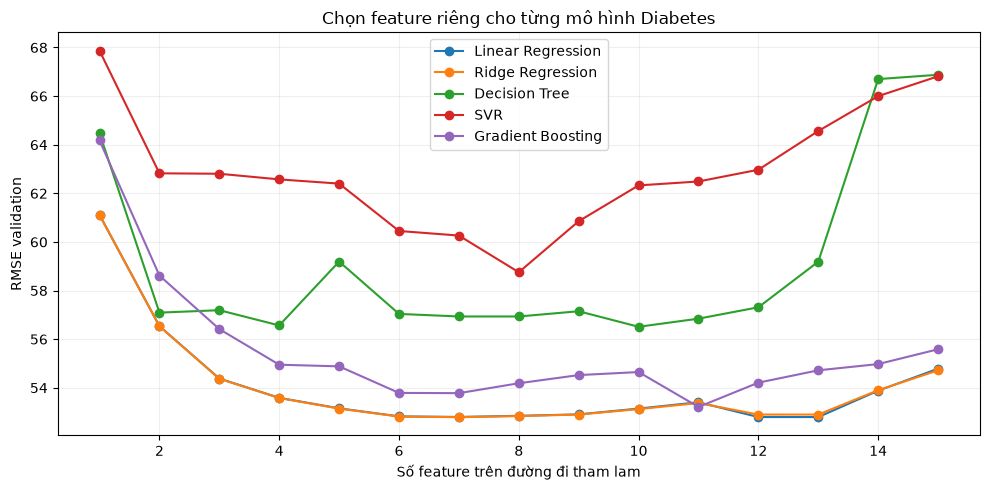

In [ ]:
reference_rows_d = []
for model_name, regressor in diabetes_models.items():
    for set_name, cols in candidate_sets_d.items():
        cols = [col for col in X_search_d.columns if col in cols]
        model = diabetes_pipeline(X_search_d[cols], clone(regressor))
        model.fit(X_search_d[cols], y_search_d)
        reference_rows_d.append({"Mô hình": model_name, "Bộ mốc": set_name,
            "Số feature": len(cols), **metric_values(y_valid_d, model.predict(X_valid_d[cols]))})
reference_comparison_d = pd.DataFrame(reference_rows_d)
display(reference_comparison_d)
display(selection_path_d)
fig, ax = plt.subplots(figsize=(10, 5))
for name, group in selection_path_d.groupby("Mô hình", sort=False):
    ax.plot(group["Số feature"], group["RMSE"], marker="o", label=name)
ax.set(xlabel="Số feature trên đường đi tham lam", ylabel="RMSE validation",
       title="Chọn feature riêng cho từng mô hình Diabetes")
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
plt.close()

## Bước 35. Fit lại trên toàn bộ train và đánh giá test

Giữ nguyên danh sách đã chọn bằng validation, kể cả khi test không cải thiện. Không nhìn test rồi đổi lại danh sách.

In [ ]:
selected_models_d = {}
selected_predictions_d = {}
final_rows_d = []
for model_name, regressor in diabetes_models.items():
    cols = selected_features_d[model_name]
    model = diabetes_pipeline(X_fe.loc[X_train.index, cols], clone(regressor))
    model.fit(X_fe.loc[X_train.index, cols], y_train)
    predicted = model.predict(X_fe.loc[X_test.index, cols])
    train_pred = model.predict(X_fe.loc[X_train.index, cols])
    row = {"Mô hình": model_name, "Số feature": len(cols), "Features": ", ".join(cols),
           **metric_values(y_test, predicted),
           "RMSE_train": np.sqrt(mean_squared_error(y_train, train_pred)),
           "R2_train": r2_score(y_train, train_pred)}
    final_rows_d.append(row)
    selected_models_d[model_name] = model
    selected_predictions_d[model_name] = predicted
final_comparison_d = pd.DataFrame(final_rows_d)
display(final_comparison_d)
baseline_compare_d = comparison_algorithms[["Mô hình", "MAE", "RMSE", "R2"]].merge(
    final_comparison_d[["Mô hình", "Số feature", "MAE", "RMSE", "R2"]],
    on="Mô hình", suffixes=("_gốc10", "_chọn_validation"))
baseline_compare_d["Thay đổi RMSE test"] = baseline_compare_d["RMSE_chọn_validation"] - baseline_compare_d["RMSE_gốc10"]
display(baseline_compare_d)

,Mô hình,Số feature,Features,MAE,MSE,RMSE,R2,RMSE_train,R2_train
0,Linear Regression,13,"age, sex, bmi, bp, s1, s2, s3, s4, s5, s6, bp_...",43.149261,2914.044772,53.981893,0.449988,53.312560,0.532251
1,Ridge Regression,7,"age, sex, bmi, bp, s3, s5, serum_std",43.217397,2868.737120,53.560593,0.458540,54.152044,0.517404
2,Decision Tree,10,"age, sex, bmi, bp, s4, s6, bmi_squared, bp_squ...",50.162019,4159.944805,64.497634,0.214831,50.795730,0.575372
3,SVR,8,"age, sex, bmi, bp, s3, s4, bmi_squared, bp_squ...",48.572208,3717.676065,60.972749,0.298307,42.520596,0.702455
4,Gradient Boosting,11,"age, sex, bmi, bp, s1, s3, s4, s5, bp_squared,...",43.423048,2980.561562,54.594520,0.437434,40.948864,0.724045


,Mô hình,MAE_gốc10,RMSE_gốc10,R2_gốc10,Số feature,MAE_chọn_validation,RMSE_chọn_validation,R2_chọn_validation,Thay đổi RMSE test
0,Gradient Boosting,42.822271,52.893935,0.471935,11,43.423048,54.594520,0.437434,1.700585
1,Ridge Regression,42.811999,53.777454,0.454147,7,43.217397,53.560593,0.458540,-0.216861
2,Linear Regression,42.794095,53.853446,0.452603,13,43.149261,53.981893,0.449988,0.128447
3,Decision Tree,43.441655,54.753049,0.434162,10,50.162019,64.497634,0.214831,9.744585
4,SVR,46.382479,62.332106,0.266670,8,48.572208,60.972749,0.298307,-1.359358


# 7. Bài 4 — Xây dựng mô hình hồi quy giá nhà

## Yêu cầu

Thực hiện pipeline trên kc_house_data.csv, gồm dữ liệu gốc, Feature Engineering, Feature Selection, nhiều thuật toán và so sánh các chỉ số.

Đặt kc_house_data.csv cùng thư mục notebook hoặc thư mục cha. Nếu dùng Colab, tải CSV lên thư mục làm việc.

## Bước 36. Nạp và kiểm tra dữ liệu giá nhà

Target là price. Kiểm tra thiếu, trùng, giá không hợp lệ, ngày và số phòng ngủ bất thường; giữ các quan sát chưa xác minh là sai.

In [ ]:
csv_candidates = [Path('kc_house_data.csv'), Path('../kc_house_data.csv')]
csv_path = next((p for p in csv_candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError('Hãy đặt kc_house_data.csv cùng thư mục notebook hoặc thư mục cha; trên Colab hãy tải CSV lên.')
house_raw = pd.read_csv(csv_path)
print('Shape gốc:', house_raw.shape)
display(house_raw.head())
print('Kiểu dữ liệu:')
print(house_raw.dtypes)
print('Giá trị thiếu theo cột:')
print(house_raw.isna().sum())
dup_full = int(house_raw.duplicated().sum())
dup_id = int(house_raw['id'].duplicated().sum())
invalid_price = int((house_raw['price'].isna() | (house_raw['price'] <= 0)).sum())
print('Trùng toàn bộ hàng:', dup_full, '| id xuất hiện lại:', dup_id)
print('Giá không hợp lệ:', invalid_price)
house = house_raw.drop_duplicates().copy()
house = house.loc[house['price'].notna() & (house['price'] > 0)].reset_index(drop=True)
house_dates = pd.to_datetime(house['date'], format='%Y%m%dT%H%M%S', errors='coerce')
print('Ngày không đọc được:', int(house_dates.isna().sum()))
print('Số dòng bedrooms > 20:', int((house['bedrooms'] > 20).sum()))
print('Số dòng bedrooms = 0:', int((house['bedrooms'] == 0).sum()))
print('Dữ liệu sau kiểm tra:', house.shape)
display(house.describe().T)

Shape gốc: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


Kiểu dữ liệu:
id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object
Giá trị thiếu theo cột:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64
Trùng toàn 

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


## Bước 37. Phân phối giá nhà và các đầu vào

Quan sát price, diện tích, số phòng và grade. Không tự động xóa nhà đắt hoặc lớn.

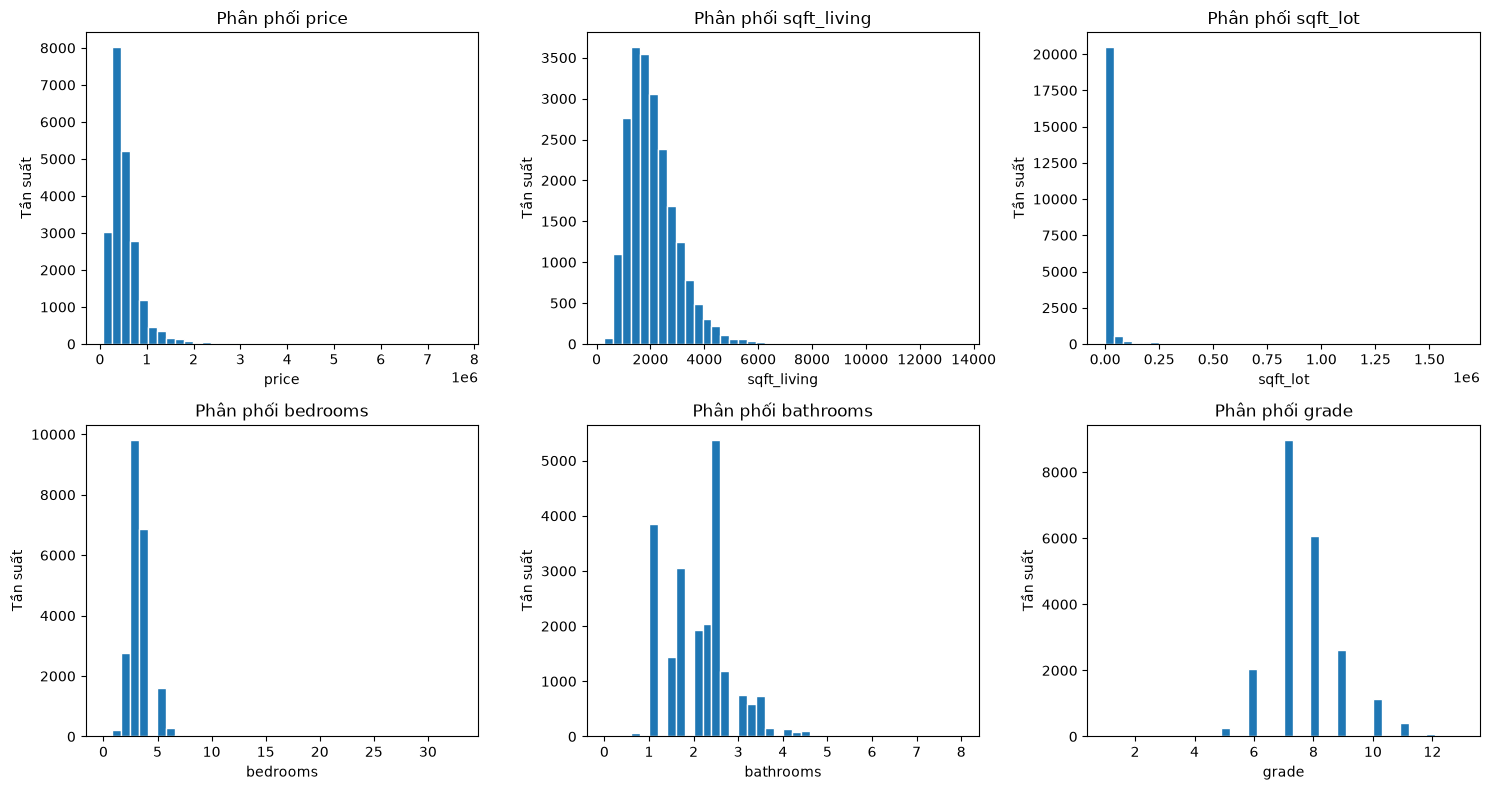

In [ ]:
house_eda_cols = ['price', 'sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms', 'grade']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, house_eda_cols):
    ax.hist(house[col], bins=40, edgecolor='white')
    ax.set(title=f'Phân phối {col}', xlabel=col, ylabel='Tần suất')
plt.tight_layout()
plt.show()
plt.close("all")

## Bước 38. Ngoại lệ theo IQR

Dùng cùng quy tắc IQR như Diabetes.

In [ ]:
outlier_house_rows = []
for col in house_eda_cols:
    q1, q3 = house[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_house_rows.append({'Bien': col, 'Nguong_duoi': lo, 'Nguong_tren': hi,
                               'So_outlier': int(((house[col] < lo) | (house[col] > hi)).sum())})
house_outliers = pd.DataFrame(outlier_house_rows)
display(house_outliers)

,Bien,Nguong_duoi,Nguong_tren,So_outlier
0,price,-162625.000,1129575.000,1146
1,sqft_living,-257.500,4234.500,572
2,sqft_lot,-3432.000,19160.000,2425
3,bedrooms,1.500,5.500,546
4,bathrooms,0.625,3.625,571
5,grade,5.500,9.500,1911


## Bước 39. Boxplot ngoại lệ của các cột giá nhà

Điểm đỏ là ngoại lệ theo từng cột. Các quan sát chưa chứng minh sai vẫn được giữ; không coi mọi nhà đắt là lỗi.

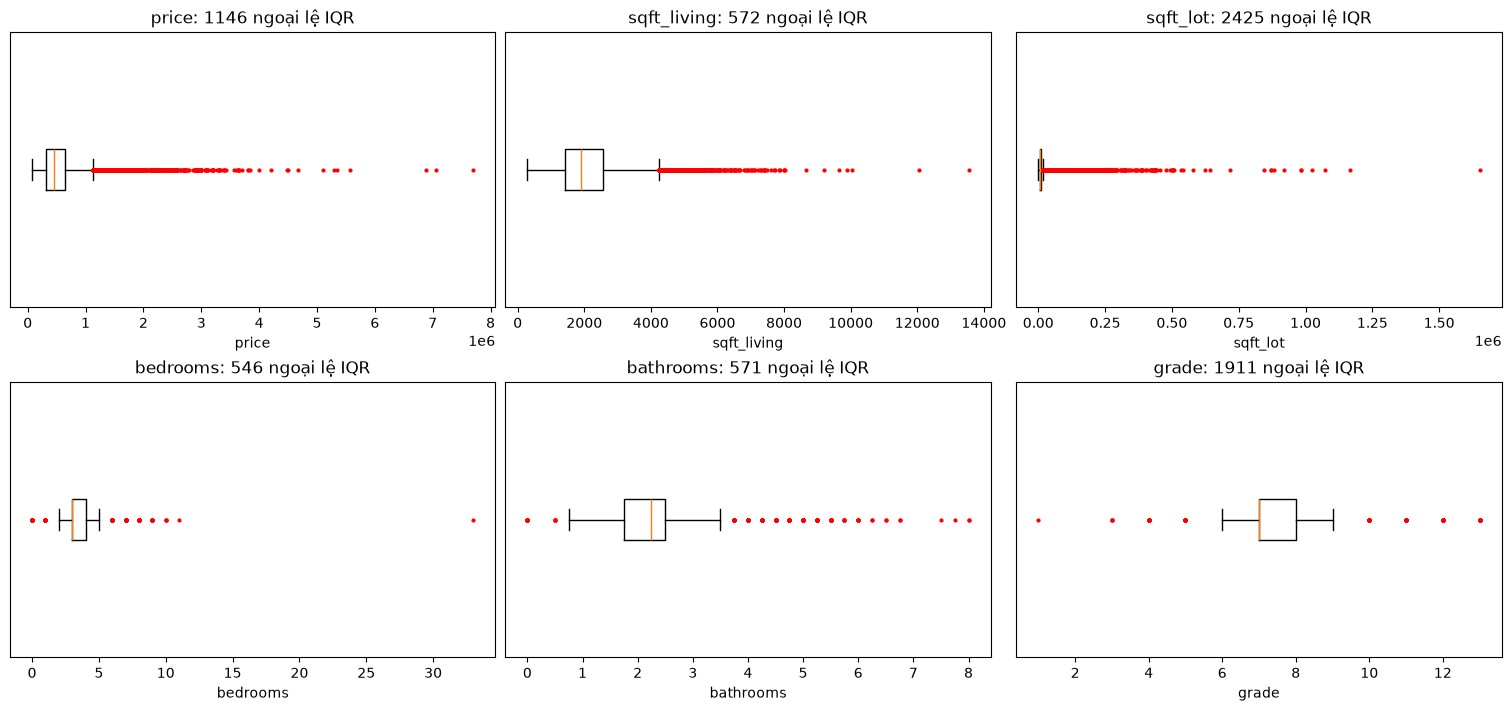

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), layout="constrained")
for ax, col in zip(axes.flat, house_eda_cols):
    q1, q3 = house[col].quantile([.25, .75])
    iqr = q3 - q1
    count = int(((house[col] < q1 - 1.5 * iqr) |
                 (house[col] > q3 + 1.5 * iqr)).sum())
    ax.boxplot(house[col], orientation="horizontal", whis=1.5,
               flierprops={"marker": "o", "markerfacecolor": "red",
                           "markeredgecolor": "red", "markersize": 2})
    ax.set(title=f"{col}: {count} ngoại lệ IQR", xlabel=col, yticks=[])
plt.show()
plt.close("all")

## Bước 40. Tương quan với price

Không dùng id và không coi zipcode là đại lượng số liên tục khi tính tương quan.

In [ ]:
house_numeric_eda = house.drop(columns=['id', 'date', 'zipcode'])
house_corr_full = house_numeric_eda.corr()['price'].drop('price').sort_values(key=np.abs, ascending=False)
display(house_corr_full.to_frame('corr_price_toan_bo_du_lieu'))

,corr_price_toan_bo_du_lieu
sqft_living,0.702035
grade,0.667434
sqft_above,0.605567
sqft_living15,0.585379
bathrooms,0.525138
view,0.397293
sqft_basement,0.323816
bedrooms,0.308350
lat,0.307003
waterfront,0.266369


## Bước 41. Scatter plot với price

Xem quan hệ giữa giá và diện tích ở, grade, vị trí.

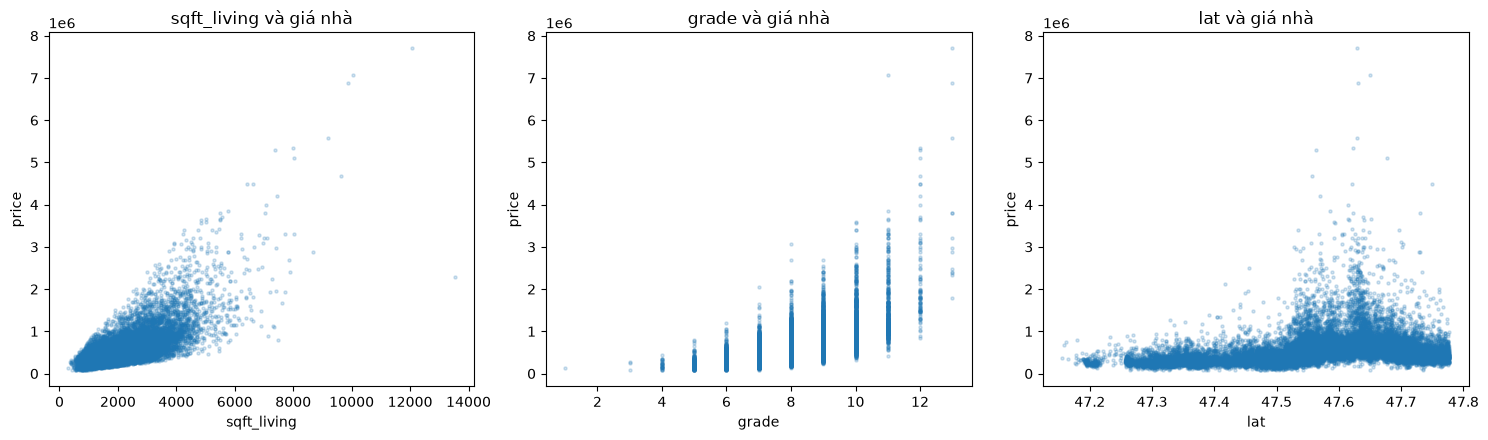

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ['sqft_living', 'grade', 'lat']):
    ax.scatter(house[col], house['price'], s=5, alpha=.2)
    ax.set(xlabel=col, ylabel='price', title=f'{col} và giá nhà')
plt.tight_layout()
plt.show()
plt.close("all")

### Nhận xét EDA

Giá và diện tích có đuôi dài về phía giá trị cao. Diện tích ở và grade có liên hệ dương với giá, nhưng riêng một biến chưa quyết định được giá. Có 177 dòng lặp id; đây có thể là các giao dịch khác nhau của cùng nhà.

## Bước 42. Chia train/test giá nhà

Chia theo nhóm id để cùng một nhà không nằm ở cả train và test. test_size=0,2, random_state=42; tỉ lệ số hàng có thể lệch nhẹ vì chia theo nhóm.

In [ ]:
y_h = house['price'].copy()
X_h = house.drop(columns=['price', 'id', 'date']).copy()
X_h['zipcode'] = X_h['zipcode'].astype(str)
splitter = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
idx_train_h, idx_test_h = next(splitter.split(X_h, y_h, groups=house['id']))
print('Train:', len(idx_train_h), '| Test:', len(idx_test_h))
shared_ids = set(house.iloc[idx_train_h]['id']) & set(house.iloc[idx_test_h]['id'])
print('Số id chung train/test:', len(shared_ids))

Train: 17289 | Test: 4324
Số id chung train/test: 0


## Bước 43. Tạo các đặc trưng mới

Thêm năm/tháng bán, tuổi nhà, sửa chữa, tầng hầm, tỉ lệ, log diện tích, bình phương diện tích và tương tác grade × diện tích. Không dùng price để tạo đầu vào.

In [ ]:
X_h_fe = X_h.copy()
sale_year = house_dates.dt.year
X_h_fe['sale_year'] = sale_year
X_h_fe['sale_month'] = house_dates.dt.month
X_h_fe['house_age'] = (sale_year - house['yr_built']).clip(lower=0)
X_h_fe['is_renovated'] = (house['yr_renovated'] > 0).astype(int)
X_h_fe['renovation_age'] = np.where(house['yr_renovated'] > 0,
    (sale_year - house['yr_renovated']).clip(lower=0), X_h_fe['house_age'])
X_h_fe['has_basement'] = (house['sqft_basement'] > 0).astype(int)
X_h_fe['bathrooms_per_bedroom'] = house['bathrooms'] / house['bedrooms'].replace(0, np.nan)
X_h_fe['living_to_lot_ratio'] = house['sqft_living'] / house['sqft_lot'].replace(0, np.nan)
X_h_fe['log_sqft_living'] = np.log1p(house['sqft_living'])
X_h_fe['log_sqft_lot'] = np.log1p(house['sqft_lot'])
X_h_fe['living_squared'] = house['sqft_living'] ** 2
X_h_fe['grade_living'] = house['grade'] * house['sqft_living']
X_h_fe = X_h_fe.replace([np.inf, -np.inf], np.nan)
display(X_h_fe.head())

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age,is_renovated,renovation_age,has_basement,bathrooms_per_bedroom,living_to_lot_ratio,log_sqft_living,log_sqft_lot,living_squared,grade_living
0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650,2014,10,59,0,59,0,0.333333,0.208850,7.074117,8.639588,1392400,8260
1,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014,12,63,1,23,1,0.750000,0.354874,7.852050,8.887791,6604900,17990
2,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062,2015,2,82,0,82,0,0.500000,0.077000,6.647688,9.210440,592900,4620
3,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000,2014,12,49,0,49,1,0.750000,0.392000,7.581210,8.517393,3841600,13720
4,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503,2015,2,28,0,28,0,0.666667,0.207921,7.427144,8.997271,2822400,13440


## Bước 44. Chọn đặc trưng

Chọn top 8 biến số theo |Pearson| trên train và giữ zipcode dạng phân loại.

In [ ]:
# Chọn top 8 biến số theo |Pearson| trên train; giữ zipcode để biểu diễn vùng.
numeric_h = X_h.select_dtypes(include=np.number).columns.tolist()
corr_train_h = X_h.iloc[idx_train_h][numeric_h].corrwith(y_h.iloc[idx_train_h]).abs().sort_values(ascending=False)
top8_h = corr_train_h.head(8).index.tolist()
selected_h = top8_h + ['zipcode']
print('Top 8 biến số chỉ tính trên train:', top8_h)
display(corr_train_h.to_frame('abs_corr_train'))

Top 8 biến số chỉ tính trên train: ['sqft_living', 'grade', 'sqft_above', 'sqft_living15', 'bathrooms', 'view', 'sqft_basement', 'lat']


,abs_corr_train
sqft_living,0.701125
grade,0.665195
sqft_above,0.603750
sqft_living15,0.588034
bathrooms,0.521774
view,0.399147
sqft_basement,0.323901
lat,0.307477
bedrooms,0.302796
waterfront,0.274488


## Bước 45. Chuẩn bị ba bộ đầu vào

So sánh bộ gốc, Feature Engineering và Feature Selection.

In [ ]:
house_sets = {
    "Gốc": X_h,
    "Feature Engineering": X_h_fe,
    "Feature Selection": X_h[selected_h]
}
print("Số cột trước mã hóa:", {name: data.shape[1] for name, data in house_sets.items()})

Số cột trước mã hóa: {'Gốc': 18, 'Feature Engineering': 30, 'Feature Selection': 9}


## Bước 46. Tiền xử lý trong Pipeline

Biến số: điền thiếu bằng trung vị train và chuẩn hóa. zipcode: mã hóa One-Hot, chấp nhận mã mới ở test. Pipeline chỉ học tiền xử lý trên train.

In [ ]:
def house_pipeline(X, regressor):
    num = X.select_dtypes(include=np.number).columns.tolist()
    cat = [col for col in X.columns if col not in num]
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    preprocessing = ColumnTransformer([('num', num_pipe, num), ('cat', cat_pipe, cat)])
    return Pipeline([('preprocessing', preprocessing), ('model', regressor)])

## Bước 47. Baseline Linear Regression

Khai báo → fit → predict → đánh giá với bộ đầu vào gốc.

In [ ]:
baseline_house = house_pipeline(X_h, LinearRegression())
baseline_house.fit(X_h.iloc[idx_train_h], y_h.iloc[idx_train_h])
baseline_house_pred = baseline_house.predict(X_h.iloc[idx_test_h])
display(pd.DataFrame([metric_values(y_h.iloc[idx_test_h], baseline_house_pred)]))

,MAE,MSE,RMSE,R2
0,96342.907551,2.633585e+10,162283.246355,0.811443


## Bước 48. Khai báo các thuật toán giá nhà

Đặt tham số trước thí nghiệm; SVR chuẩn hóa nhãn trong train và trả dự đoán về thang giá gốc.

In [ ]:
house_models = {
        'Linear Regression': LinearRegression(),
        'Ridge Regression': Ridge(alpha=10.0),
        'Decision Tree': DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=SEED),
        'SVR': TransformedTargetRegressor(regressor=SVR(kernel='rbf', C=10, epsilon=.1, cache_size=256), transformer=StandardScaler()),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=.05, max_depth=3, random_state=SEED)
    }

## Bước 49. Huấn luyện và đánh giá 15 cấu hình

5 thuật toán × 3 bộ đầu vào. Mọi cấu hình dùng cùng các hàng train/test. So sánh thêm metric train để xem khả năng khái quát.

In [ ]:
house_results = []
house_predictions = {}

for feature_name, data in house_sets.items():
    X_train_house = data.iloc[idx_train_h]
    X_test_house = data.iloc[idx_test_h]
    y_train_house = y_h.iloc[idx_train_h]
    y_test_house = y_h.iloc[idx_test_h]

    for model_name, regressor in house_models.items():
        model = house_pipeline(data, clone(regressor))
        model.fit(X_train_house, y_train_house)
        prediction = model.predict(X_test_house)
        train_prediction = model.predict(X_train_house)
        row = {"Bộ đặc trưng": feature_name, "Mô hình": model_name,
               **metric_values(y_test_house, prediction)}
        row["RMSE_train"] = np.sqrt(mean_squared_error(y_train_house, train_prediction))
        row["R2_train"] = r2_score(y_train_house, train_prediction)
        house_results.append(row)
        house_predictions[(feature_name, model_name)] = prediction

comparison_house = pd.DataFrame(house_results).sort_values("RMSE").reset_index(drop=True)
display(comparison_house)

,Bộ đặc trưng,Mô hình,MAE,MSE,RMSE,R2,RMSE_train,R2_train
0,Feature Engineering,Gradient Boosting,75282.011431,1.580122e+10,125702.903624,0.886868,110092.091721,0.909241
1,Gốc,Gradient Boosting,75588.342111,1.595045e+10,126295.089245,0.885799,111983.709832,0.906096
2,Feature Selection,Gradient Boosting,83045.012859,1.888357e+10,137417.510783,0.864799,128187.400012,0.876954
3,Feature Engineering,Linear Regression,85523.392945,2.011950e+10,141843.223675,0.855950,144130.807371,0.844443
4,Feature Engineering,Ridge Regression,85405.259125,2.040933e+10,142861.229517,0.853875,145203.792009,0.842118
5,Gốc,SVR,72429.681396,2.210290e+10,148670.429212,0.841750,72546.642779,0.960590
6,Feature Engineering,SVR,73240.326822,2.280574e+10,151015.691801,0.836718,67886.523594,0.965490
7,Gốc,Linear Regression,96342.907551,2.633585e+10,162283.246355,0.811443,160438.157259,0.807251
8,Gốc,Ridge Regression,96380.591550,2.659094e+10,163067.287590,0.809617,161058.692197,0.805757
9,Feature Selection,SVR,78895.603135,2.764068e+10,166254.858165,0.802101,85919.224709,0.944721


## Bước 50. So sánh kết quả theo bộ đặc trưng

RMSE thấp hơn tốt hơn; R² cao hơn tốt hơn.

Bộ đặc trưng,Feature Engineering,Feature Selection,Gốc
Mô hình,,,
Decision Tree,166633.812846,186394.871384,171692.197392
Gradient Boosting,125702.903624,137417.510783,126295.089245
Linear Regression,141843.223675,172872.067219,162283.246355
Ridge Regression,142861.229517,173660.871974,163067.287590
SVR,151015.691801,166254.858165,148670.429212


Bộ đặc trưng,Feature Engineering,Feature Selection,Gốc
Mô hình,,,
Decision Tree,0.801198,0.751250,0.788945
Gradient Boosting,0.886868,0.864799,0.885799
Linear Regression,0.855950,0.786034,0.811443
Ridge Regression,0.853875,0.784077,0.809617
SVR,0.836718,0.802101,0.841750


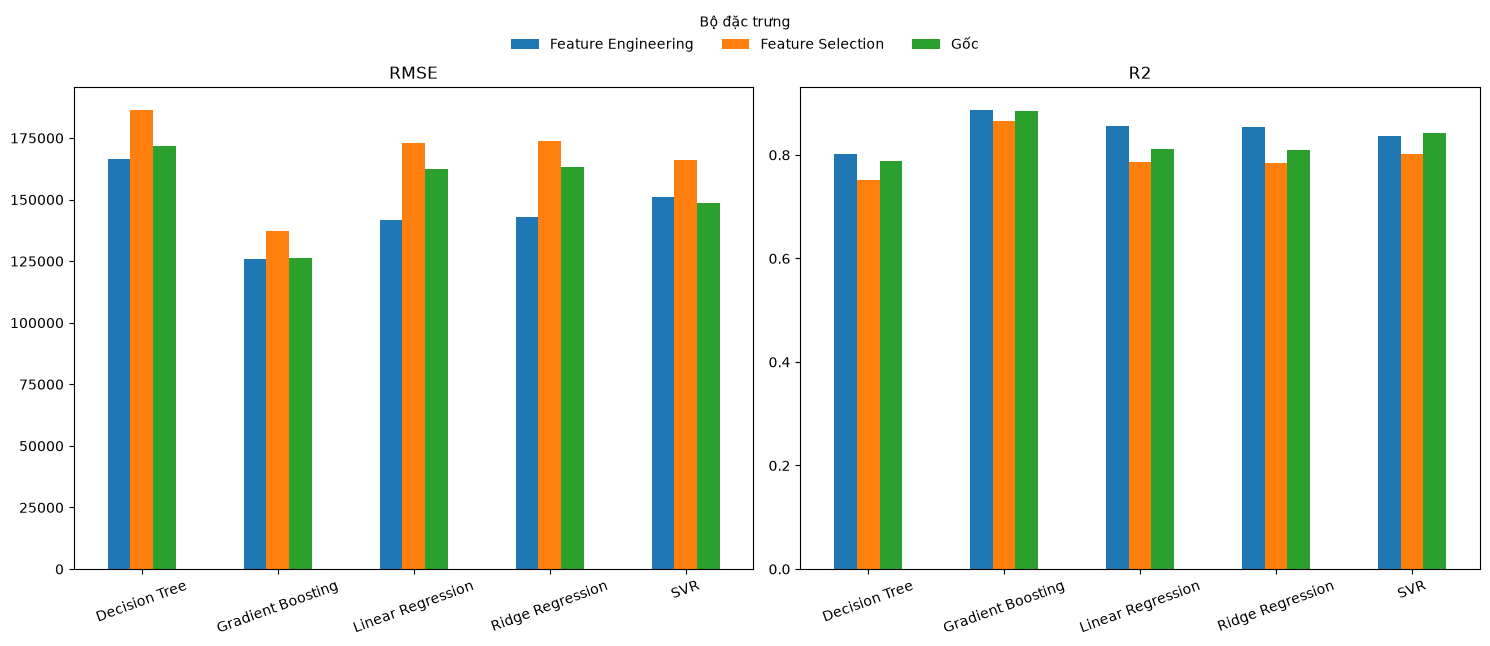

In [ ]:
display(comparison_house.pivot(index="Mô hình", columns="Bộ đặc trưng", values="RMSE"))
display(comparison_house.pivot(index="Mô hình", columns="Bộ đặc trưng", values="R2"))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metric in zip(axes, ["RMSE", "R2"]):
    comparison_house.pivot(index="Mô hình", columns="Bộ đặc trưng", values=metric).plot.bar(ax=ax, rot=20)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.08),
           ncol=3, frameon=False, title="Bộ đặc trưng")
plt.tight_layout()
plt.show()
plt.close()

## Bước 51. Bảng giá thực tế, dự đoán và phần dư

Chẩn đoán cấu hình có RMSE test thấp nhất trong bảng thí nghiệm.

In [ ]:
best_house = comparison_house.iloc[0]
best_key = (best_house["Bộ đặc trưng"], best_house["Mô hình"])
best_house_pred = house_predictions[best_key]
y_test_house = y_h.iloc[idx_test_h]
residuals_house = y_test_house.to_numpy() - best_house_pred
result_house = pd.DataFrame({
    "Actual": y_test_house.to_numpy(),
    "Predicted": best_house_pred,
    "Residual": residuals_house
})
print("Cấu hình RMSE test thấp nhất:", best_key)
display(result_house.head(10))

Cấu hình RMSE test thấp nhất: ('Feature Engineering', 'Gradient Boosting')


,Actual,Predicted,Residual
0,510000.0,5.300165e+05,-20016.503494
1,395000.0,4.085485e+05,-13548.474220
2,233000.0,2.697824e+05,-36782.389127
3,696000.0,7.158881e+05,-19888.115613
4,309000.0,2.349235e+05,74076.452274
5,228000.0,2.270599e+05,940.137409
6,585000.0,4.808502e+05,104149.793315
7,885000.0,7.963789e+05,88621.058254
8,292500.0,3.038770e+05,-11377.036974
9,1325000.0,1.163650e+06,161349.796660


## Bước 52. Biểu đồ chẩn đoán giá nhà

Xem đường chéo dự đoán đúng, phần dư quanh 0 và phân phối sai số.

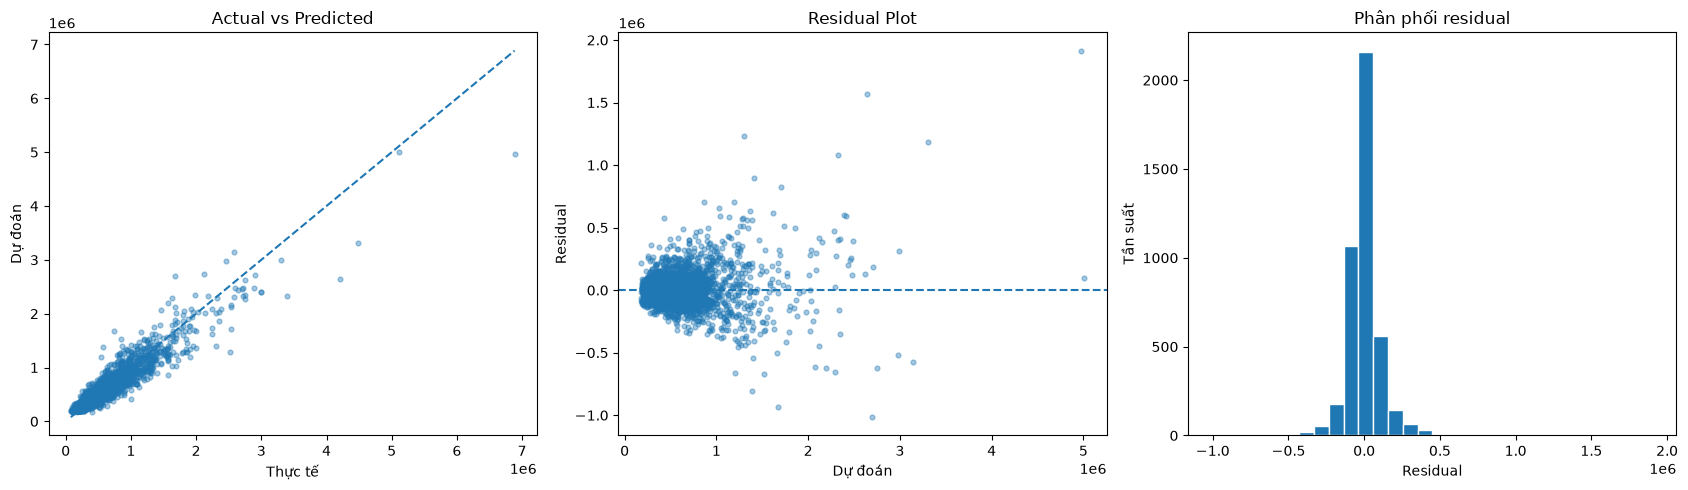

Mean residual: 1115.6181528791424


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(y_test_house, best_house_pred, alpha=0.4, s=12)
lo = min(y_test_house.min(), best_house_pred.min())
hi = max(y_test_house.max(), best_house_pred.max())
axes[0].plot([lo, hi], [lo, hi], "--")
axes[0].set(xlabel="Thực tế", ylabel="Dự đoán", title="Actual vs Predicted")
axes[1].scatter(best_house_pred, residuals_house, alpha=0.4, s=12)
axes[1].axhline(0, linestyle="--")
axes[1].set(xlabel="Dự đoán", ylabel="Residual", title="Residual Plot")
axes[2].hist(residuals_house, bins=30, edgecolor="white")
axes[2].set(xlabel="Residual", ylabel="Tần suất", title="Phân phối residual")
plt.tight_layout()
plt.show()
plt.close()
print("Mean residual:", np.mean(residuals_house))

### Nhận xét bài 4

- Gradient Boosting với Feature Engineering có RMSE test thấp nhất trong các cấu hình đã thử, khoảng 125.703; R² khoảng 0,887.
- SVR với bộ gốc có MAE thấp nhất. Xếp hạng có thể khác vì RMSE phạt sai số lớn mạnh hơn MAE.
- Feature Engineering cải thiện rõ Linear Regression; Feature Selection đơn giản theo tương quan làm mất một phần thông tin và có kết quả kém hơn bộ gốc ở đây.
- Một số căn nhà rất đắt bị dự đoán thấp đáng kể. R² cao không bảo đảm mọi mẫu có sai số nhỏ.
- Chênh lệch train/test là dấu hiệu cần kiểm tra khả năng khái quát. Trung bình phần dư gần 0 chưa đủ để kết luận mô hình tốt.
- Kết quả giới hạn trong các cấu hình đã thử. Việc chọn theo test ở đây phục vụ so sánh bài thực hành; khi triển khai, chọn bằng validation/CV trong train và đánh giá cuối trên dữ liệu độc lập.

# 8. Lựa chọn đặc trưng riêng cho từng mô hình giá nhà

15 cấu hình ở bước 49 là so ba bộ đầu vào định trước. Lựa chọn riêng cho mỗi thuật toán được thực hiện bằng cách thử thử bộ gốc 18, bộ FE 30, bộ top 8 số tính trên fit cộng zipcode, rồi chọn thêm dần từ 30 feature trước mã hóa. Zipcode được chọn như một feature gốc và mã hóa thành một khối One-Hot trong Pipeline.

Để thời gian tìm kiếm phù hợp với bài thực hành, lấy **3.000 nhóm id cho fit và 1.500 nhóm id cho validation**, chỉ từ train ngoài cùng. Các nhóm còn lại trong train không dùng ở bước tìm kiếm, nhưng toàn bộ train ngoài cùng được dùng khi fit mô hình cuối. Số hàng có thể lớn hơn số nhóm vì có giao dịch lặp. Đây là lựa chọn trên mẫu của train, chưa chứng minh bộ tối ưu trên toàn bộ dữ liệu.

Chọn thêm dần tối đa **8 feature** cho mỗi thuật toán, đồng thời đánh giá ba bộ mốc. Bước đầu thử từng feature trong cả 30 cột, các lượt sau thử từng cột còn lại để bổ sung. Quy trình không xét mọi tổ hợp 9–29 cột. Bộ được chọn cuối có thể là một bộ ít cột trên đường đi hoặc một bộ mốc 18/30 cột nếu bộ mốc có RMSE validation tốt hơn.

## Bước 53. Lấy mẫu fit validation theo nhóm từ train

Test ngoài cùng được giữ riêng. In số id giao nhau thực tế để kiểm tra cách chia.

In [ ]:
outer_train_features_h = X_h_fe.iloc[idx_train_h]
outer_train_target_h = y_h.iloc[idx_train_h]
outer_train_groups_h = house.iloc[idx_train_h]["id"]
inner_sampler_h = GroupShuffleSplit(n_splits=1, train_size=3000,
                                     test_size=1500, random_state=SEED)
search_pos_h, valid_pos_h = next(inner_sampler_h.split(
    outer_train_features_h, outer_train_target_h, groups=outer_train_groups_h))
X_search_h = outer_train_features_h.iloc[search_pos_h]
y_search_h = outer_train_target_h.iloc[search_pos_h]
X_valid_h = outer_train_features_h.iloc[valid_pos_h]
y_valid_h = outer_train_target_h.iloc[valid_pos_h]
fit_ids_h = set(outer_train_groups_h.iloc[search_pos_h])
valid_ids_h = set(outer_train_groups_h.iloc[valid_pos_h])
test_ids_h = set(house.iloc[idx_test_h]["id"])
print("Fit tìm feature:", len(X_search_h), "hàng,", len(fit_ids_h), "id")
print("Validation:", len(X_valid_h), "hàng,", len(valid_ids_h), "id")
print("Train cuối:", len(idx_train_h), "hàng | Test cuối:", len(idx_test_h), "hàng")
print("Id chung fit/validation:", len(fit_ids_h & valid_ids_h))
print("Id của mẫu chọn feature nằm trong test:", len((fit_ids_h | valid_ids_h) & test_ids_h))
# Lấy cột số bằng dtype; zipcode là chuỗi nên không xếp hạng như số.
inner_numeric_h = X_h.select_dtypes(include=np.number).columns.tolist()
top8_inner_h = X_search_h[inner_numeric_h].corrwith(y_search_h).abs().sort_values(
    ascending=False).head(8).index.tolist()
candidate_sets_h = {"Gốc 18": X_h.columns.tolist(),
                    "Feature Engineering 30": X_h_fe.columns.tolist(),
                    "Top 8 trên fit và zipcode": top8_inner_h + ["zipcode"]}
display(pd.DataFrame([{"Bộ mốc": label, "Số feature": len(cols),
                      "Features": ", ".join(cols)}
                     for label, cols in candidate_sets_h.items()]))

Fit tìm feature: 3025 hàng, 3000 id
Validation: 1507 hàng, 1500 id
Train cuối: 17289 hàng | Test cuối: 4324 hàng
Id chung fit/validation: 0
Id của mẫu chọn feature nằm trong test: 0


,Bộ mốc,Số feature,Features
0,Gốc 18,18,"bedrooms, bathrooms, sqft_living, sqft_lot, fl..."
1,Feature Engineering 30,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl..."
2,Top 8 trên fit và zipcode,9,"sqft_living, grade, sqft_living15, sqft_above,..."


## Bước 54. Chọn thêm dần riêng cho từng mô hình giá nhà

Mỗi mô hình được đánh giá độc lập trên các bộ mốc và các bộ tạo bởi quy trình chọn thêm dần.

In [ ]:
selected_features_h = {}
best_validation_h = []
trials_h = []
paths_h = []
for model_name, regressor in house_models.items():
    cols, best, trials, path = search_features(
        model_name, regressor, X_search_h, y_search_h, X_valid_h, y_valid_h,
        house_pipeline, candidate_sets_h, max_features=8)
    selected_features_h[model_name] = cols
    best_validation_h.append(best)
    trials_h.append(trials)
    paths_h.append(path)
all_trials_h = pd.concat(trials_h, ignore_index=True)
selection_path_h = pd.concat(paths_h, ignore_index=True)
best_validation_h = pd.DataFrame(best_validation_h)
print("Tổng số bộ thực sự đã fit trên mẫu train:", len(all_trials_h))
display(best_validation_h[["Mô hình", "Nguồn thử", "Số feature", "Features",
                           "MAE", "MSE", "RMSE", "R2", "Số bộ đã thử"]])

Tổng số bộ thực sự đã fit trên mẫu train: 1075


,Mô hình,Nguồn thử,Số feature,Features,MAE,MSE,RMSE,R2,Số bộ đã thử
0,Linear Regression,Feature Engineering 30,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",84018.545242,1.832281e+10,135361.787546,0.866942,215
1,Ridge Regression,Feature Engineering 30,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",88063.803513,1.997736e+10,141341.298008,0.854926,215
2,Decision Tree,Chọn thêm dần,8,"view, condition, lat, long, sqft_living15, log...",90788.847133,2.640060e+10,162482.620116,0.808282,215
3,SVR,Chọn thêm dần,8,"sqft_living, waterfront, zipcode, long, sqft_l...",78018.146362,2.261352e+10,150377.928756,0.835783,215
4,Gradient Boosting,Chọn thêm dần,8,"sqft_living, waterfront, view, sqft_above, zip...",80869.798821,1.732858e+10,131638.061173,0.874162,215


## Bước 55. So các bộ mốc và đường đi chọn feature

Bảng này và đường đi chỉ sử dụng validation nội bộ. Không xếp hạng feature bằng nhãn test.

,Mô hình,Nguồn thử,Số feature,Features,MAE,MSE,RMSE,R2
0,Linear Regression,Gốc 18,18,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",94114.589953,2.282367e+10,151075.064109,0.834257
1,Linear Regression,Feature Engineering 30,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",84018.545242,1.832281e+10,135361.787546,0.866942
2,Linear Regression,Top 8 trên fit và zipcode,9,"bathrooms, sqft_living, view, grade, sqft_abov...",99730.197039,2.815549e+10,167795.978653,0.795538
215,Ridge Regression,Gốc 18,18,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",97322.791599,2.484364e+10,157618.658659,0.819588
216,Ridge Regression,Feature Engineering 30,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",88063.803513,1.997736e+10,141341.298008,0.854926
217,Ridge Regression,Top 8 trên fit và zipcode,9,"bathrooms, sqft_living, view, grade, sqft_abov...",103465.773279,3.041765e+10,174406.566871,0.779110
430,Decision Tree,Gốc 18,18,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",102652.428051,3.323416e+10,182302.382147,0.758657
431,Decision Tree,Feature Engineering 30,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",94331.316325,2.803466e+10,167435.526507,0.796415
432,Decision Tree,Top 8 trên fit và zipcode,9,"bathrooms, sqft_living, view, grade, sqft_abov...",113000.712444,4.833273e+10,219847.068866,0.649013
645,SVR,Gốc 18,18,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",80270.044166,2.852678e+10,168898.722956,0.792841


,Mô hình,Lượt,Feature thêm,Features,Số feature,MAE,MSE,RMSE,R2
0,Linear Regression,1,grade_living,grade_living,1,161370.550112,5.600833e+10,236660.789259,0.593273
1,Linear Regression,2,zipcode,"zipcode, grade_living",2,98549.527802,2.725409e+10,165088.138427,0.802084
2,Linear Regression,3,waterfront,"waterfront, zipcode, grade_living",3,94263.009691,2.126661e+10,145830.772364,0.845564
3,Linear Regression,4,view,"waterfront, view, zipcode, grade_living",4,90703.022513,2.016942e+10,142019.086781,0.853532
4,Linear Regression,5,log_sqft_living,"waterfront, view, zipcode, log_sqft_living, gr...",5,89564.879502,1.943638e+10,139414.403421,0.858855
5,Linear Regression,6,condition,"waterfront, view, condition, zipcode, log_sqft...",6,87562.249354,1.882886e+10,137218.284656,0.863267
6,Linear Regression,7,sqft_basement,"waterfront, view, condition, sqft_basement, zi...",7,87155.881099,1.868451e+10,136691.307698,0.864315
7,Linear Regression,8,sale_year,"waterfront, view, condition, sqft_basement, zi...",8,87083.335498,1.856016e+10,136235.688288,0.865218
8,Ridge Regression,1,grade_living,grade_living,1,161251.267725,5.602189e+10,236689.432541,0.593175
9,Ridge Regression,2,zipcode,"zipcode, grade_living",2,100818.577526,2.902148e+10,170356.910195,0.789249


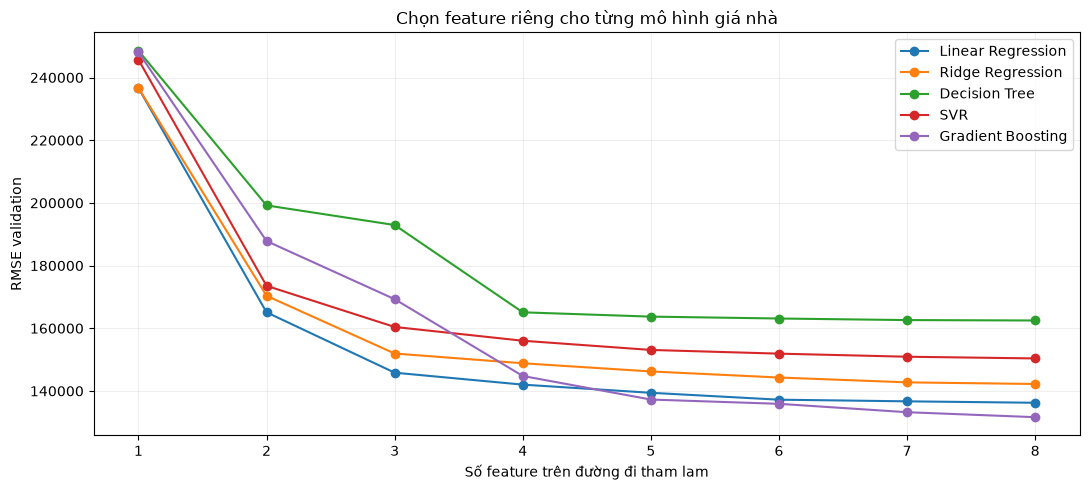

In [ ]:
reference_comparison_h = all_trials_h[all_trials_h["Nguồn thử"].isin(candidate_sets_h)].copy()
display(reference_comparison_h)
display(selection_path_h)
fig, ax = plt.subplots(figsize=(11, 5))
for name, group in selection_path_h.groupby("Mô hình", sort=False):
    ax.plot(group["Số feature"], group["RMSE"], marker="o", label=name)
ax.set(xlabel="Số feature trên đường đi tham lam", ylabel="RMSE validation",
       title="Chọn feature riêng cho từng mô hình giá nhà")
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
plt.close()

## Bước 56. Fit trên toàn bộ train và đánh giá test cuối

Dùng tất cả 17.289 hàng train ngoài cùng, không chỉ mẫu tìm feature. Danh sách chọn được giữ nguyên trước khi tính test.

In [ ]:
selected_models_h = {}
selected_predictions_h = {}
final_rows_h = []
for model_name, regressor in house_models.items():
    cols = selected_features_h[model_name]
    X_final_train_h = X_h_fe.iloc[idx_train_h][cols]
    X_final_test_h = X_h_fe.iloc[idx_test_h][cols]
    model = house_pipeline(X_final_train_h, clone(regressor))
    model.fit(X_final_train_h, y_h.iloc[idx_train_h])
    predicted = model.predict(X_final_test_h)
    train_pred = model.predict(X_final_train_h)
    final_rows_h.append({"Mô hình": model_name, "Số feature": len(cols),
        "Features": ", ".join(cols), **metric_values(y_h.iloc[idx_test_h], predicted),
        "RMSE_train": np.sqrt(mean_squared_error(y_h.iloc[idx_train_h], train_pred)),
        "R2_train": r2_score(y_h.iloc[idx_train_h], train_pred)})
    selected_models_h[model_name] = model
    selected_predictions_h[model_name] = predicted
final_comparison_h = pd.DataFrame(final_rows_h)
display(final_comparison_h)
baseline_rows_h = comparison_house[comparison_house["Bộ đặc trưng"] == "Gốc"]
baseline_compare_h = baseline_rows_h[["Mô hình", "MAE", "RMSE", "R2"]].merge(
    final_comparison_h[["Mô hình", "Số feature", "MAE", "RMSE", "R2"]],
    on="Mô hình", suffixes=("_gốc18", "_chọn_validation"))
baseline_compare_h["Thay đổi RMSE test"] = baseline_compare_h["RMSE_chọn_validation"] - baseline_compare_h["RMSE_gốc18"]
display(baseline_compare_h)

,Mô hình,Số feature,Features,MAE,MSE,RMSE,R2,RMSE_train,R2_train
0,Linear Regression,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",85523.392945,2.011950e+10,141843.223675,0.855950,144130.807371,0.844443
1,Ridge Regression,30,"bedrooms, bathrooms, sqft_living, sqft_lot, fl...",85405.259125,2.040933e+10,142861.229517,0.853875,145203.792009,0.842118
2,Decision Tree,8,"view, condition, lat, long, sqft_living15, log...",93367.424222,2.787975e+10,166972.310114,0.800389,145908.318866,0.840582
3,SVR,8,"sqft_living, waterfront, zipcode, long, sqft_l...",76815.198773,2.127575e+10,145862.104471,0.847672,105097.776853,0.917289
4,Gradient Boosting,8,"sqft_living, waterfront, view, sqft_above, zip...",84215.890344,1.926525e+10,138799.323537,0.862066,123998.981560,0.884864


,Mô hình,MAE_gốc18,RMSE_gốc18,R2_gốc18,Số feature,MAE_chọn_validation,RMSE_chọn_validation,R2_chọn_validation,Thay đổi RMSE test
0,Gradient Boosting,75588.342111,126295.089245,0.885799,8,84215.890344,138799.323537,0.862066,12504.234292
1,SVR,72429.681396,148670.429212,0.841750,8,76815.198773,145862.104471,0.847672,-2808.324742
2,Linear Regression,96342.907551,162283.246355,0.811443,30,85523.392945,141843.223675,0.855950,-20440.022680
3,Ridge Regression,96380.591550,163067.287590,0.809617,30,85405.259125,142861.229517,0.853875,-20206.058073
4,Decision Tree,96182.711041,171692.197392,0.788945,8,93367.424222,166972.310114,0.800389,-4719.887278


## Bước 57. Chẩn đoán phần dư cho từng mô hình đã chọn

Vẽ cả năm mô hình thay vì chỉ dòng test RMSE nhỏ nhất. Mỗi hàng gồm actual vs predicted và residual vs predicted.

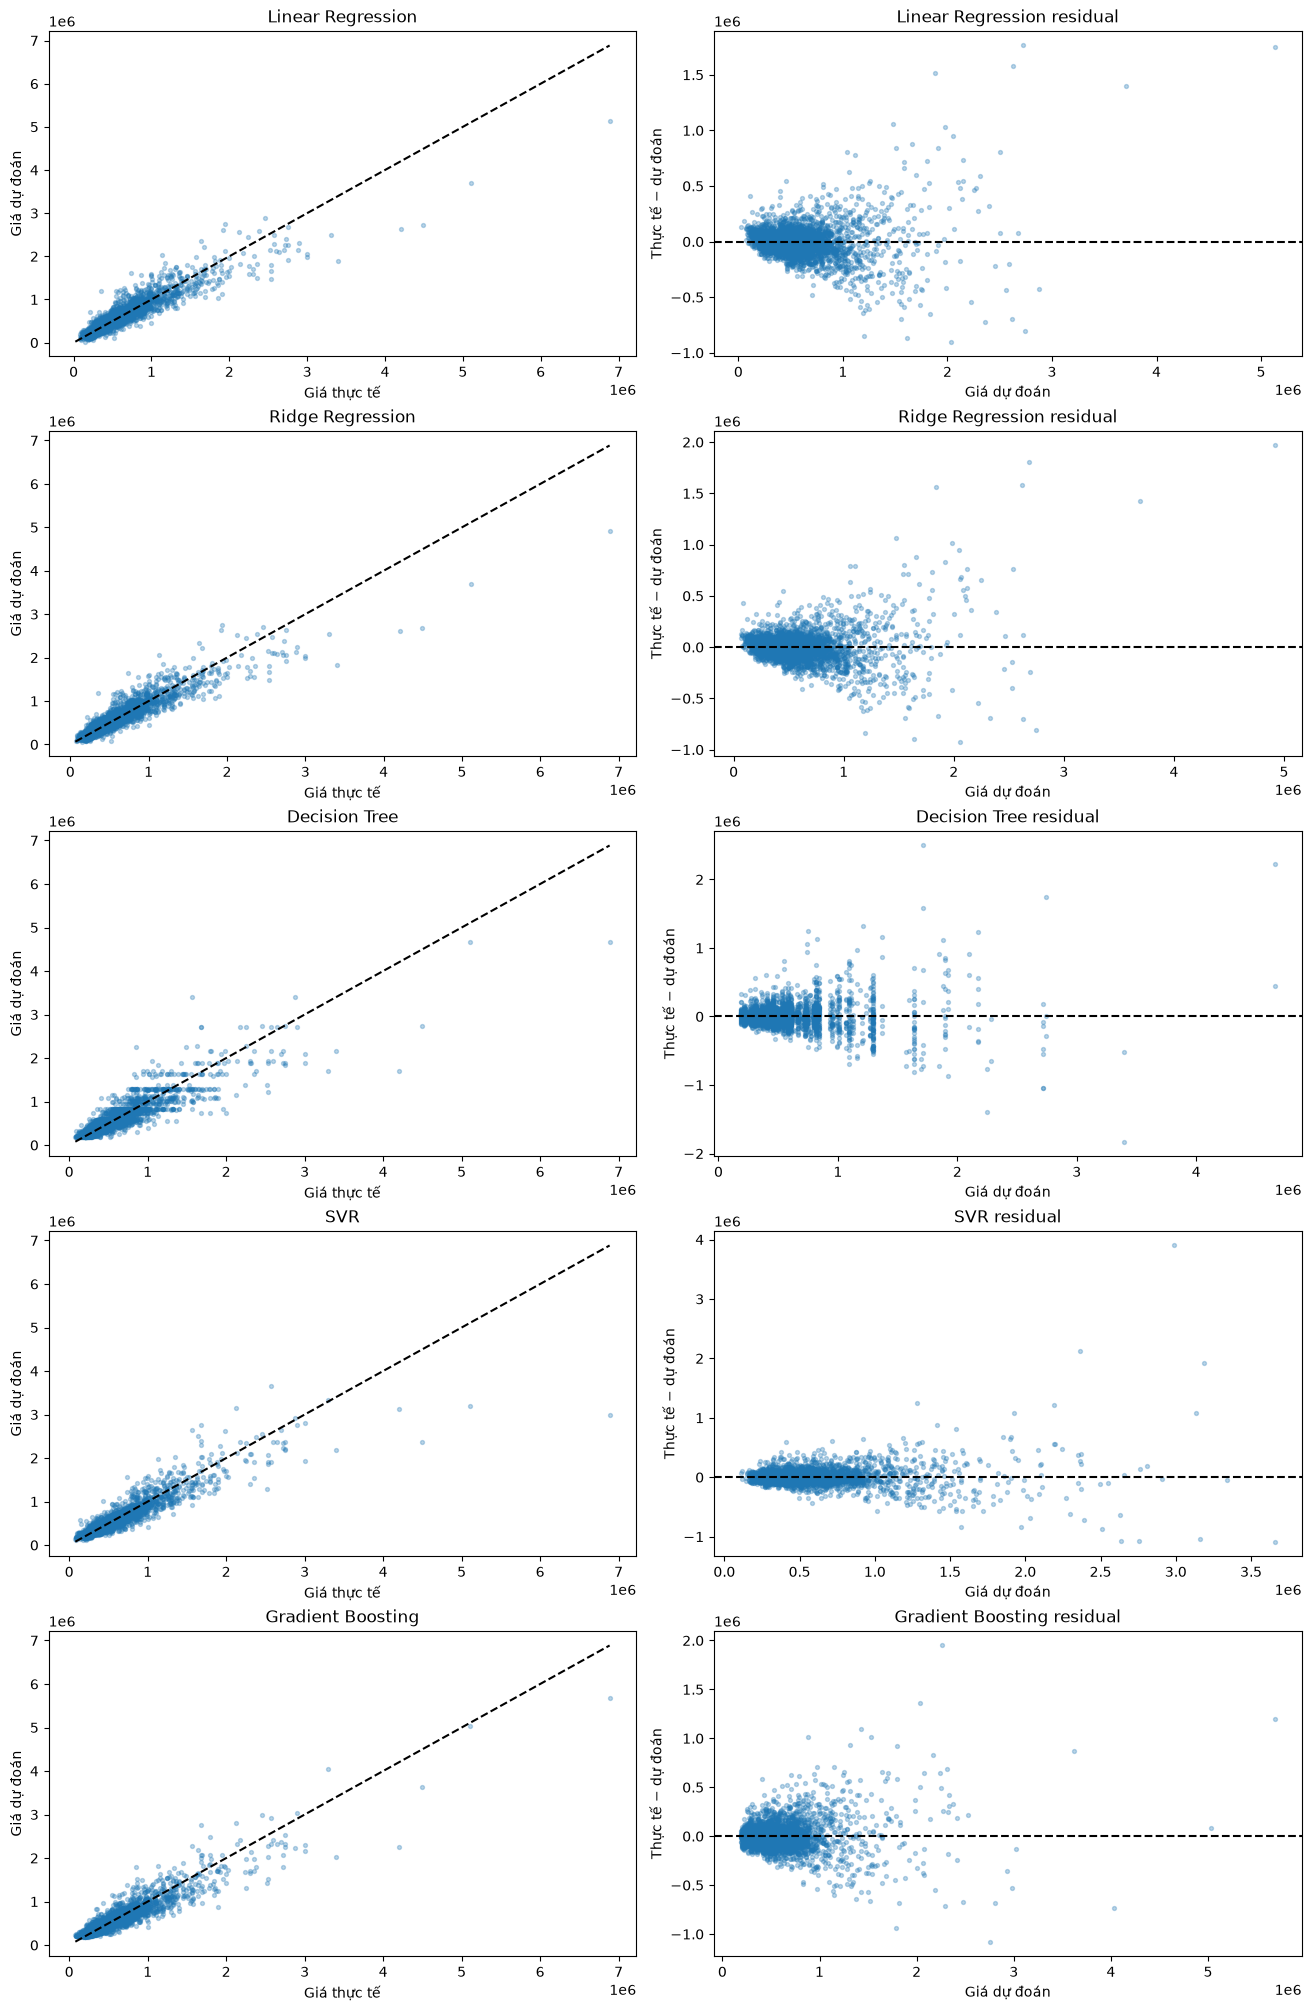

In [ ]:
actual_h = y_h.iloc[idx_test_h].to_numpy()
fig, axes = plt.subplots(5, 2, figsize=(13, 20), layout="constrained")
for row, (name, predicted) in enumerate(selected_predictions_h.items()):
    residual = actual_h - predicted
    lo = min(actual_h.min(), predicted.min())
    hi = max(actual_h.max(), predicted.max())
    axes[row, 0].scatter(actual_h, predicted, s=8, alpha=.3)
    axes[row, 0].plot([lo, hi], [lo, hi], "k--")
    axes[row, 0].set(title=name, xlabel="Giá thực tế", ylabel="Giá dự đoán")
    axes[row, 1].scatter(predicted, residual, s=8, alpha=.3)
    axes[row, 1].axhline(0, color="black", linestyle="--")
    axes[row, 1].set(title=name + " residual", xlabel="Giá dự đoán", ylabel="Thực tế − dự đoán")
plt.show()
plt.close("all")

# 9. Tổng hợp kết quả và kết luận

Bộ feature được chọn bằng validation trong train; các metric test là đánh giá sau khi fit lại trên toàn bộ train. Danh sách đặc trưng được cố định trước khi đánh giá test.

## Diabetes

Chọn thêm dần qua 1–15 feature, cùng năm bộ mốc; validation nội bộ gồm 71 mẫu.

Đã đánh giá **612 bộ feature** tính tổng cho năm mô hình; các bộ trùng trong một mô hình được dùng lại kết quả.

| Mô hình | Số feature | MAE | RMSE | R2 |
| --- | --- | --- | --- | --- |
| Linear Regression | 13 | 43.15 | 53.98 | 0.4500 |
| Ridge Regression | 7 | 43.22 | 53.56 | 0.4585 |
| Decision Tree | 10 | 50.16 | 64.50 | 0.2148 |
| SVR | 8 | 48.57 | 60.97 | 0.2983 |
| Gradient Boosting | 11 | 43.42 | 54.59 | 0.4374 |

### Feature được chọn riêng cho từng mô hình

- **Linear Regression** — 13 feature: `age, sex, bmi, bp, s1, s2, s3, s4, s5, s6, bp_squared, serum_mean, serum_std`.

- **Ridge Regression** — 7 feature: `age, sex, bmi, bp, s3, s5, serum_std`.

- **Decision Tree** — 10 feature: `age, sex, bmi, bp, s4, s6, bmi_squared, bp_squared, bmi_bp, serum_mean`.

- **SVR** — 8 feature: `age, sex, bmi, bp, s3, s4, bmi_squared, bp_squared`.

- **Gradient Boosting** — 11 feature: `age, sex, bmi, bp, s1, s3, s4, s5, bp_squared, serum_mean, serum_std`.

### Nhận xét so với baseline trên cùng test

- **Gradient Boosting**: RMSE test tăng **1.7006** so với baseline đầu vào gốc.

- **Ridge Regression**: RMSE test giảm **0.2169** so với baseline đầu vào gốc.

- **Linear Regression**: RMSE test tăng **0.1284** so với baseline đầu vào gốc.

- **Decision Tree**: RMSE test tăng **9.7446** so với baseline đầu vào gốc.

- **SVR**: RMSE test giảm **1.3594** so với baseline đầu vào gốc.

Nếu RMSE test tăng, đó là kết quả cần báo cáo, không phải lý do nhìn test rồi chọn lại feature. Chọn tốt trên một validation hữu hạn có thể không tốt hơn trên test. Tìm kiếm tham lam chưa bảo đảm tập tối ưu toàn cục.

## Giá nhà

Tìm feature trên 3.000 nhóm fit và 1.500 nhóm validation trong train; chọn thêm dần tối đa 8 feature cùng ba bộ mốc 18/30/9 cột.

Đã đánh giá **1075 bộ feature** tính tổng cho năm mô hình; các bộ trùng trong một mô hình được dùng lại kết quả.

| Mô hình | Số feature | MAE | RMSE | R2 |
| --- | --- | --- | --- | --- |
| Linear Regression | 30 | 85,523.39 | 141,843.22 | 0.8560 |
| Ridge Regression | 30 | 85,405.26 | 142,861.23 | 0.8539 |
| Decision Tree | 8 | 93,367.42 | 166,972.31 | 0.8004 |
| SVR | 8 | 76,815.20 | 145,862.10 | 0.8477 |
| Gradient Boosting | 8 | 84,215.89 | 138,799.32 | 0.8621 |

### Feature được chọn riêng cho từng mô hình

- **Linear Regression** — 30 feature: `bedrooms, bathrooms, sqft_living, sqft_lot, floors, waterfront, view, condition, grade, sqft_above, sqft_basement, yr_built, yr_renovated, zipcode, lat, long, sqft_living15, sqft_lot15, sale_year, sale_month, house_age, is_renovated, renovation_age, has_basement, bathrooms_per_bedroom, living_to_lot_ratio, log_sqft_living, log_sqft_lot, living_squared, grade_living`.

- **Ridge Regression** — 30 feature: `bedrooms, bathrooms, sqft_living, sqft_lot, floors, waterfront, view, condition, grade, sqft_above, sqft_basement, yr_built, yr_renovated, zipcode, lat, long, sqft_living15, sqft_lot15, sale_year, sale_month, house_age, is_renovated, renovation_age, has_basement, bathrooms_per_bedroom, living_to_lot_ratio, log_sqft_living, log_sqft_lot, living_squared, grade_living`.

- **Decision Tree** — 8 feature: `view, condition, lat, long, sqft_living15, log_sqft_living, living_squared, grade_living`.

- **SVR** — 8 feature: `sqft_living, waterfront, zipcode, long, sqft_living15, log_sqft_living, living_squared, grade_living`.

- **Gradient Boosting** — 8 feature: `sqft_living, waterfront, view, sqft_above, zipcode, lat, long, sqft_living15`.

### Nhận xét so với baseline trên cùng test

- **Gradient Boosting**: RMSE test tăng **12,504.2343** so với baseline đầu vào gốc.

- **SVR**: RMSE test giảm **2,808.3247** so với baseline đầu vào gốc.

- **Linear Regression**: RMSE test giảm **20,440.0227** so với baseline đầu vào gốc.

- **Ridge Regression**: RMSE test giảm **20,206.0581** so với baseline đầu vào gốc.

- **Decision Tree**: RMSE test giảm **4,719.8873** so với baseline đầu vào gốc.

Nếu RMSE test tăng, đó là kết quả cần báo cáo, không phải lý do nhìn test rồi chọn lại feature. Chọn tốt trên một validation hữu hạn có thể không tốt hơn trên test. Tìm kiếm tham lam chưa bảo đảm tập tối ưu toàn cục.

## Kết luận

Các kết quả cho thấy bộ đặc trưng phù hợp phụ thuộc vào thuật toán và cách đánh giá. Feature Engineering hoặc Feature Selection có thể cải thiện một số chỉ số, nhưng không bảo đảm mọi mô hình có sai số test nhỏ hơn baseline. Khi lựa chọn bằng một validation hữu hạn, hiệu quả trên test có thể giảm dù điểm validation tốt hơn.

Quy trình chọn thêm dần là tìm kiếm tham lam trong phạm vi đã nêu, chưa bảo đảm tối ưu mọi tập con. Ở giá nhà, lựa chọn được thực hiện trên mẫu nhóm trong train; mô hình cuối được huấn luyện lại trên toàn bộ train ngoài cùng. Các biến năm và tháng bán chỉ phù hợp nếu thời điểm giao dịch dự định đã biết lúc dự đoán.

R² không phải tỷ lệ số mẫu dự đoán đúng. Ngoại lệ theo IQR chưa chứng minh quan sát sai, và trung bình phần dư gần 0 chưa bảo đảm MAE hoặc RMSE nhỏ. Kết luận được giới hạn trong dữ liệu, các cấu hình và cách chia đã sử dụng.
